# Ноутбук 4. Тесты простоты и генерация параметров

В ноутбуке 3 мы изучили функцию Эйлера, порядок элемента и первообразные корни. Здесь мы исследуем тесты Ферма и Миллера—Рабина, применим критерий Люка и построим параметры для обмена Диффи—Хеллмана.

## 4.0. Подключение библиотеки курса

### Задание 4.0

Импортируйте из `crypto_math.number_theory` функции `gcd`, `mod_pow`, `random_exact_bits`, `primes`, `is_prime_fast`, `smallest_factor`, `decompose`, `euler_phi`, `multiplicative_order`, `is_primitive_root` и `primitive_root`. Проверьте функции ноутбука 3 на малых примерах.

In [1]:
import random
import time
from math import isqrt
from random import randint

from crypto_math.number_theory import (
    gcd, mod_pow, random_exact_bits,                     # из ноутбука 1
    is_prime_fast, primes,                              # из ноутбука 2
    smallest_factor, decompose, euler_phi,               # из ноутбука 3
    multiplicative_order, is_primitive_root, primitive_root,
)

assert gcd(30, 18) == 6
assert mod_pow(7, 13, 23) == pow(7, 13, 23)
assert [n for n in range(50) if is_prime_fast(n)] == primes(49)
assert smallest_factor(105) == 3
assert decompose(360) == {2: 3, 3: 2, 5: 1}
assert euler_phi(36) == 12
assert multiplicative_order(5, 17) == 16
assert multiplicative_order(4, 17, 16) == 4
assert is_primitive_root(2, 9) and not is_primitive_root(4, 9)
assert primitive_root(9) == 2 and primitive_root(8) is None
print("crypto_math подключена")


crypto_math подключена


## 4.1. Тест Ферма

По малой теореме Ферма для простого $p$ и целого $a$, взаимно простого с $p$, выполняется сравнение $a^{p-1}\equiv1\pmod p$. Если $1\le a<n$ и $a^{n-1}\not\equiv1\pmod n$, число $n>1$ составное. Это позволяет обнаружить составность без факторизации [[3]](#lit_3).

Вычислите остатки через `pow(a, n-1, n)` для пар $(a,n)$: $(3,37)$, $(17,101)$, $(303,101)$, $(5,91)$ и $(7,12319)$. Объясните результат для $a=303$ с учётом условия взаимной простоты.

In [2]:
# Ваше решение

# Малая теорема Ферма обещает остаток 1 только при gcd(a, n) = 1.
# Пара (303, 101) этому условию не удовлетворяет, поэтому теорема о ней молчит.
pairs = [(3, 37), (17, 101), (303, 101), (5, 91), (7, 12319)]
for a, n in pairs:
    remainder = pow(a, n - 1, n)
    print(f"a={a}, n={n}: a^(n-1) mod n = {remainder}, gcd(a, n) = {gcd(a, n)}")

assert pow(3, 36, 37) == 1
assert pow(17, 100, 101) == 1
assert pow(303, 100, 101) == 0
assert pow(5, 90, 91) == 64
assert pow(7, 12318, 12319) == 1331
print(
    "У 37 и 101 остаток равен 1: необходимое свойство простого выполнено.\n"
    "303 делится на 101, остаток 0. Это не доказывает составность 101: посылка теоремы ложна.\n"
    "Основания 5 для 91 и 7 для 12319 дают остаток, отличный от 1. Оба числа составные."
)


a=3, n=37: a^(n-1) mod n = 1, gcd(a, n) = 1
a=17, n=101: a^(n-1) mod n = 1, gcd(a, n) = 1
a=303, n=101: a^(n-1) mod n = 0, gcd(a, n) = 101
a=5, n=91: a^(n-1) mod n = 64, gcd(a, n) = 1
a=7, n=12319: a^(n-1) mod n = 1331, gcd(a, n) = 1
У 37 и 101 остаток равен 1: необходимое свойство простого выполнено.
303 делится на 101, остаток 0. Это не доказывает составность 101: посылка теоремы ложна.
Основания 5 для 91 и 7 для 12319 дают остаток, отличный от 1. Оба числа составные.


Для 91 и 12319 найдены свидетели составности. Вычислите теперь остаток для числа 91 и основания 3.

In [3]:
# Ваше решение

# То же составное 91, но другое основание. Один свидетель не описывает все основания.
remainder = pow(3, 90, 91)
print(f"3^90 mod 91 = {remainder}")
assert remainder == 1
print(
    "Остаток равен 1: по основанию 3 число 91 проходит проверку Ферма,\n"
    "хотя основание 5 уже обнаружило его составность."
)


3^90 mod 91 = 1
Остаток равен 1: по основанию 3 число 91 проходит проверку Ферма,
хотя основание 5 уже обнаружило его составность.


Число 91 проходит проверку по основанию 3. Переберите основания от 1 до 19 и определите, какие из них обнаруживают составность 91.

In [4]:
# Ваше решение

# Свидетель составности — основание из 1..19, для которого остаток не равен 1.
witnesses = [a for a in range(1, 20) if pow(a, 90, 91) != 1]
passed = [a for a in range(1, 20) if pow(a, 90, 91) == 1]
print("обнаруживают составность 91:", witnesses)
print("проходят проверку:", passed)
assert 5 in witnesses and 3 in passed
print("Результат одного раунда для 91 зависит от выбранного основания.")


обнаруживают составность 91: [2, 5, 6, 7, 8, 11, 13, 14, 15, 18, 19]
проходят проверку: [1, 3, 4, 9, 10, 12, 16, 17]
Результат одного раунда для 91 зависит от выбранного основания.


Результат одного раунда для составного числа может зависеть от выбранного основания.

### Определение (псевдопростые числа)  
>Нечётное составное число $N$ называют *псевдопростым по основанию* $a \in \mathbb{Z}$ (НОД$(a,N)=1$), если выполняется сравнение
$$a^{N-1} \equiv 1 \pmod{N}. $$

Заметим, что число $341$, будучи *псевдопростым по основанию* $2$, не будет *псевдопростым*,
например, по основанию $3$, поскольку $$3^{341-1} \not \equiv 1 \pmod{341}. $$

Вычислите оба остатка по модулю 341.

In [5]:
# Ваше решение

# 341 = 11*31 псевдопросто по основанию 2 и не псевдопросто по основанию 3.
print(f"2^340 mod 341 = {pow(2, 340, 341)}")
print(f"3^340 mod 341 = {pow(3, 340, 341)}")
assert pow(2, 340, 341) == 1
assert pow(3, 340, 341) != 1
print("По основанию 2 сравнение Ферма выполняется, по основанию 3 — нет.")


2^340 mod 341 = 1
3^340 mod 341 = 56
По основанию 2 сравнение Ферма выполняется, по основанию 3 — нет.


### Задание 4.1

Найдите наименьшее нечётное составное число, псевдопростое по основанию 3. Для точной проверки составности используйте `is_prime_fast`.

In [6]:
# Ваше решение

# Псевдопростое по основанию 3: нечётное составное n, взаимно простое с 3,
# для которого 3^{n-1} ≡ 1 (mod n). Идём по возрастанию, первый успех — наименьший.
n = 9
while True:
    if gcd(3, n) == 1 and not is_prime_fast(n) and mod_pow(3, n - 1, n) == 1:
        break
    n += 2

print("наименьшее нечётное составное, псевдопростое по основанию 3:", n)
assert n == 91
assert not is_prime_fast(n) and mod_pow(3, n - 1, n) == 1


наименьшее нечётное составное, псевдопростое по основанию 3: 91


### Задание 4.2. Основания, обманывающие проверку Ферма

Число $n=121=11^2$ составное. Найдите все основания $a$, $1\le a\le120$, взаимно простые со 121, для которых
$$a^{120}\equiv1\pmod{121}.$$
На таких основаниях число 121 проходит проверку Ферма, несмотря на составность.

1. Постройте элементы группы $(\mathbb Z/121\mathbb Z)^*$ с помощью библиотечной `gcd`. Найдите указанные основания и их долю среди элементов группы. Размер группы вычислите библиотечной `euler_phi`.
2. Теперь предположим, что основание выбирается равномерно вызовом `randint(2, 119)`. Сколько значений может быть выбрано? Какие из найденных оснований остались в этом диапазоне? Найдите вероятность того, что одна проверка пропустит составное число 121.
3. Объясните различие двух долей: какие основания исключены из диапазона выбора, а какие входят в него, но не являются элементами группы?

**Самопроверка.** 

Среди элементов группы — **9,09%**; при выборе через `randint(2,119)` — **6,78%**.

In [7]:
# Ваше решение

def format_percent(numerator, denominator):
    """Процент с двумя знаками. Округление считается в целых, без двоичного float."""
    hundredths = (numerator * 10000 + denominator // 2) // denominator
    return f"{hundredths // 100},{hundredths % 100:02d}%"


n = 121
# Группа (Z/121Z)* — вычеты 1..120, взаимно простые с модулем.
group = [a for a in range(1, n) if gcd(a, n) == 1]
# Лжец Ферма внутри группы: степень n-1 всё же даёт 1, хотя 121 составное.
liars = [a for a in group if mod_pow(a, n - 1, n) == 1]
phi = euler_phi(n)
assert group[0] == 1 and len(group) == phi == 110
assert len(liars) == 10

# randint(2, 119) выбирает из 118 значений. Концы 1 и 120 в этот диапазон не входят.
choices = list(range(2, 120))
liars_in_choices = [a for a in liars if 2 <= a <= 119]
assert len(choices) == 118
assert len(liars_in_choices) == 8

print("лжецы Ферма в группе:", liars)
print("из них в диапазоне 2..119:", liars_in_choices)
print(
    f"доля среди элементов группы: {len(liars)}/{phi} = {format_percent(len(liars), phi)}"
)
print(
    "вероятность пропуска при одном randint(2, 119): "
    f"{len(liars_in_choices)}/{len(choices)} = "
    f"{format_percent(len(liars_in_choices), len(choices))}"
)
assert format_percent(len(liars), phi) == "9,09%"
assert format_percent(len(liars_in_choices), len(choices)) == "6,78%"

excluded = [a for a in liars if a == 1 or a == n - 1]
non_units = [a for a in choices if gcd(a, n) != 1]
print("исключены из выбора, но являются лжецами группы:", excluded)
print("входят в диапазон выбора, но не лежат в группе:", non_units)
print(
    "Доли разные, потому что знаменатели — разные множества.\n"
    "1 и 120 лежат в группе и проходят проверку, но randint их не берёт.\n"
    "Кратные 11 лежат в диапазоне выбора, однако не обратимы и проверку не проходят."
)


лжецы Ферма в группе: [1, 3, 9, 27, 40, 81, 94, 112, 118, 120]
из них в диапазоне 2..119: [3, 9, 27, 40, 81, 94, 112, 118]
доля среди элементов группы: 10/110 = 9,09%
вероятность пропуска при одном randint(2, 119): 8/118 = 6,78%
исключены из выбора, но являются лжецами группы: [1, 120]
входят в диапазон выбора, но не лежат в группе: [11, 22, 33, 44, 55, 66, 77, 88, 99, 110]
Доли разные, потому что знаменатели — разные множества.
1 и 120 лежат в группе и проходят проверку, но randint их не берёт.
Кратные 11 лежат в диапазоне выбора, однако не обратимы и проверку не проходят.


### Задание 4.3 

    
Найдите все псевдопростые числа по основанию $7$ в интервале от $8$ до $10000$. Источник: [2, пример 5.3](#lit_2) — Маховенко Е. Б. «Теоретико-числовые методы в криптографии».

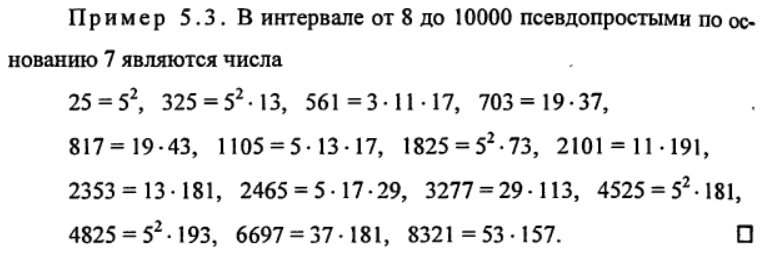

In [8]:
# Ваше решение

# Псевдопростое по основанию 7 на отрезке 8..10000: нечётное составное n,
# взаимно простое с 7, для которого 7^{n-1} ≡ 1 (mod n).
pseudoprimes = []
for n in range(9, 10001, 2):
    if gcd(7, n) != 1:
        continue
    if not is_prime_fast(n) and mod_pow(7, n - 1, n) == 1:
        pseudoprimes.append(n)

print("псевдопростые по основанию 7 от 8 до 10000:")
print(pseudoprimes)
assert pseudoprimes[0] == 25
assert 561 in pseudoprimes
assert all(
    (not is_prime_fast(n)) and gcd(7, n) == 1 and mod_pow(7, n - 1, n) == 1
    for n in pseudoprimes
)
print(f"таких чисел: {len(pseudoprimes)}. 561 — число Кармайкла, оно тоже в списке.")


псевдопростые по основанию 7 от 8 до 10000:
[25, 325, 561, 703, 817, 1105, 1825, 2101, 2353, 2465, 3277, 4525, 4825, 6697, 8321]
таких чисел: 15. 561 — число Кармайкла, оно тоже в списке.


Последовательно проверяя разные основания, можно искать свидетеля составности числа.

### Алгоритм. Тест Ферма

Источник: [1, §4.2.1, определения 4.6–4.7, пример 4.8, алгоритм 4.9](#lit_1) — Menezes, van Oorschot, Vanstone, *Handbook of Applied Cryptography*.

**Свидетель составности и лжец Ферма.** Пусть n — нечётное составное число, $1\le a\le n-1$.

- Если $a^{n-1}\not\equiv1\pmod n$, основание a — **свидетель составности Ферма**: нарушение необходимого свойства простых чисел доказывает составность n.
- Если $a^{n-1}\equiv1\pmod n$, число n — **псевдопростое по основанию a**, а основание a называют **лжецом Ферма**. Это название предполагает, что составность n уже известна. Если статус n неизвестен, говорим лишь: «проверка по основанию a пройдена».

Второе сравнение само обеспечивает $\gcd(a,n)=1$: общий простой делитель a и n сделал бы сравнение невозможным. Например, $341=11\cdot31$, но $2^{340}\equiv1\pmod{341}$ [1, пример 4.8].

**Тест Ферма (алгоритм)** Для нечётного $n\ge5$ и целого $t\ge1$:

1. Повторить t раз:
   - независимо и равномерно выбрать целое a из диапазона $2\le a\le n-2$;
   - вычислить $r=a^{n-1}\bmod n$;
   - если $r\ne1$, завершить тест: **n составное**.
2. Если все t проверок пройдены, завершить тест: **n прошло тест Ферма; простота не доказана**.

Диапазон исключает 0 и тривиальные основания $1,-1$. Вычислять НОД отдельно для этого алгоритма не требуется: необратимое основание всё равно даёт $r\ne1$. Самостоятельная проверка НОД возможна как дополнительная ранняя проверка.

Успех на нескольких основаниях не даёт универсальной гарантии ошибки $4^{-t}$: эта оценка относится к Миллеру—Рабину. Существуют составные числа, которые проходят проверку Ферма на всех основаниях, взаимно простых с n, — числа Кармайкла. Их рассмотрим после эксперимента.

### Задание 4.4. Реализация теста Ферма

Напишите функцию `Fermat(n, t)`, которая реализует приведённый тест Ферма.

1. Требуйте положительное целое t; при нарушении вызывайте `ValueError`.
2. Для n<2 возвращайте `False`; для n=2,3 — `True`; для остальных чётных n — `False`.
3. Для нечётного n≥5 выполняйте ровно t раундов, если свидетель составности не найден раньше. Выбирайте a через `randint(2, n-2)`, степень вычисляйте `mod_pow(a, n-1, n)` из библиотеки курса.
4. Если остаток не равен 1, возвращайте `False`. После всех успешных проверок возвращайте `True`.
5. Объясните, почему `True` в общем случае не доказывает простоту n.

**Проверка границ.** Убедитесь, что n=0,1,4 отклоняются, n=2,3 принимаются, а t=0 вызывает `ValueError`. Вызов `Fermat(n, 1)` должен выполнять один случайный раунд для нечётного n≥5.

In [9]:
# Ваше решение

def Fermat(n, t):
    """Тест Ферма. False — составность доказана. True — t раундов пройдены, простота не доказана."""
    # Число раундов обязано быть положительным целым, иначе тест не определён.
    if type(t) is not int or t < 1:
        raise ValueError("t должно быть положительным целым")
    if n < 2:
        return False
    # У 2 и 3 диапазон 2..n-2 пуст, но оба числа простые.
    if n in (2, 3):
        return True
    if n % 2 == 0:
        return False
    for _round in range(t):
        a = randint(2, n - 2)
        # Необратимое основание само даёт остаток, отличный от 1. Отдельный НОД не нужен.
        if mod_pow(a, n - 1, n) != 1:
            return False
    return True


assert Fermat(0, 1) is False
assert Fermat(1, 1) is False
assert Fermat(4, 1) is False
assert Fermat(2, 1) is True
assert Fermat(3, 1) is True
assert Fermat(5, 1) is True
try:
    Fermat(11, 0)
    raise AssertionError("t=0 должно быть отклонено")
except ValueError:
    pass

print(
    "True значит только то, что выбранные основания не нашли свидетеля составности.\n"
    "Конечный набор оснований простоту не доказывает: число Кармайкла проходит проверку\n"
    "на каждом основании, взаимно простом с модулем."
)


True значит только то, что выбранные основания не нашли свидетеля составности.
Конечный набор оснований простоту не доказывает: число Кармайкла проходит проверку
на каждом основании, взаимно простом с модулем.


### Задание 4.5. Эксперимент: одна проверка Ферма

Для $n=121$ выполните $N=100000$ независимых запусков проверки Ферма, выбирая в каждом запуске ровно одно основание равномерно из $2,3,\ldots,119$.

1. Найдите долю запусков, вернувших `True`: это доля случаев, когда проверка пропустила составное число 121.
2. Сравните экспериментальную долю с $8/118\approx6{,}78\%$, полученной в задании 4.2. Почему здесь нельзя сравнивать с долей $10/110$ среди элементов группы?
3. Повторите эксперимент. Почему результаты немного различаются и не обязаны точно совпадать с теоретической вероятностью?

Для одного раунда используйте `Fermat(121, 1)`. Положительный результат здесь означает пропуск составного числа, а не установление его простоты.

In [10]:
# Ваше решение

# Каждый запуск — ровно один случайный раунд, то есть выбор a из 2..119.
# True здесь означает пропуск составного 121, а не доказательство простоты.
trials = 100_000
passed_first = sum(Fermat(121, 1) for _ in range(trials))
passed_second = sum(Fermat(121, 1) for _ in range(trials))

# Теоретическая вероятность из задания 4.2 — 8/118, не 10/110.
# 10/110 считает только группу и включает основания 1 и 120, которых randint не выбирает.
print(f"первый опыт: {passed_first}/{trials}")
print(f"второй опыт: {passed_second}/{trials}")
print(f"теория randint(2, 119): 8/118 = {format_percent(8, 118)}")
print(
    "С долей 10/110 этот опыт сравнивать нельзя: эксперимент берёт a из 2..119,\n"
    "а 10/110 — доля лжецов среди элементов группы, включая 1 и 120.\n"
    "Два запуска чуть расходятся, потому что это независимые выборки.\n"
    "Они колеблются вокруг 8/118 и не обязаны попасть в неё точно."
)
# Грубая целочисленная рамка ловит сломанный тест, но не подгоняет частоты.
assert 4 * trials <= passed_first * 100 <= 12 * trials
assert 4 * trials <= passed_second * 100 <= 12 * trials


первый опыт: 6760/100000
второй опыт: 6650/100000
теория randint(2, 119): 8/118 = 6,78%
С долей 10/110 этот опыт сравнивать нельзя: эксперимент берёт a из 2..119,
а 10/110 — доля лжецов среди элементов группы, включая 1 и 120.
Два запуска чуть расходятся, потому что это независимые выборки.
Они колеблются вокруг 8/118 и не обязаны попасть в неё точно.


Рассмотрим ограничение теста Ферма на примере составного числа $41041=7\cdot11\cdot13\cdot41$.

**Область выбора основания важна.** Следующее свойство относится к основаниям, взаимно простым с n. При выборе из всех чисел 2..n−2 могут попадаться и необратимые основания, обнаруживающие составность.

Число 41041 проходит проверку Ферма для каждого основания a, взаимно простого с 41041. Основания с НОД больше 1 проверку не проходят. Поэтому частота пропуска в следующем эксперименте зависит от пространства выбора оснований.

### Определение. Числа Кармайкла

Составное число $n$ называют **числом Кармайкла**, если для каждого целого $a$, взаимно простого с $n$, выполняется $a^{n-1}\equiv1\pmod n$.

### Критерий Корсельта и числа Кармайкла

Источник определения и критерия: [1, §4.2.1, определение 4.10 и утверждения 4.11–4.12](#lit_1).

В **1899 году Альвин Корсельт** сформулировал необходимое и достаточное условие для составного числа n, удовлетворяющего сравнению Ферма для всех оснований, взаимно простых с n. Это условие называют **критерием Корсельта**. В 1910 году **Роберт Кармайкл** исследовал такие числа и указал пример $561=3\cdot11\cdot17$; они получили название чисел Кармайкла. Историческая справка — [4, введение](#lit_4).

**Критерий Корсельта** [1, утверждение 4.11]. Составное число n является числом Кармайкла тогда и только тогда, когда одновременно:

1. n **свободно от квадратов**: ни для какого простого p число $p^2$ не делит n;
2. для каждого простого делителя p числа n выполнено $p-1\mid n-1$.

Например: $30=2\cdot3\cdot5.$ Каждый простой множитель встречается один раз. Поэтому $30$ не делится ни на $2^2=4$, ни на $3^2=9$, ни на $5^2=25$. Число 30 свободно от квадратов

Таким образом, проверить, является ли составное число числом Кармайкла, можно по его разложению на простые множители. Важно требование **составности**: простое число тоже удовлетворяет этим двум условиям, но числом Кармайкла не является.

**Пример.** Для $561=3\cdot11\cdot17$ все простые множители различны, а
$$3-1=2\mid560,\qquad11-1=10\mid560,\qquad17-1=16\mid560.$$
Следовательно, 561 — число Кармайкла. Это наименьшее такое число [1, §4.2.1]. Каждое число Кармайкла имеет не менее трёх различных простых делителей [1, утверждение 4.12].

**Связь с тестом Ферма.** Для числа Кармайкла n основания $1\le a\le n-1$, взаимно простые с n, проходят проверку $a^{n-1}\equiv1\pmod n$. Свидетелями составности Ферма в этом диапазоне являются ровно основания с $\gcd(a,n)>1$. Поэтому увеличение числа раундов не помогает, если выбирать только обратимые основания. При выборе из всего диапазона $2\le a\le n-2$ составность может обнаружиться на необратимом основании; вероятность этого зависит от простых делителей n.

### Задание 4.6

Проверьте по критерию Корсельта, что 41041 — число Кармайкла. Для каждого из чисел 41041 и 671 найдите долю $P$ оснований в диапазоне от 2 до $n-2$, на которых проверка Ферма пропускает составное число. Определите минимальное число независимых раундов $t$, при котором $P^t<0{,}01$. Сопоставьте расчёт с экспериментом.

In [11]:
# Ваше решение

def is_carmichael_korselt(n):
    """Критерий Корсельта. Простое число тем же двум условиям удовлетворяет, но Кармайклом не является."""
    if is_prime_fast(n):
        return False
    factors = decompose(n)
    # Свободно от квадратов: каждый простой входит ровно один раз.
    if any(exponent != 1 for exponent in factors.values()):
        return False
    # Для каждого простого p | n нужно p-1 | n-1.
    return all((n - 1) % (prime - 1) == 0 for prime in factors)


assert is_carmichael_korselt(561)
assert is_carmichael_korselt(41041)
assert not is_carmichael_korselt(671)
print("41041 проходит критерий Корсельта, 671 — нет: 60 не делит 670.")
print("разложение 671:", decompose(671), "; 670 % 60 =", 670 % 60)


def fermat_pass_count(n):
    """Сколько оснований из 2..n-2 дают a^{n-1} ≡ 1. Это числитель доли пропуска."""
    return sum(1 for a in range(2, n - 1) if mod_pow(a, n - 1, n) == 1)


def minimal_rounds(passed, total):
    """Наименьшее t, при котором (passed/total)^t < 1/100. Сравнение только в целых."""
    t = 1
    left = passed * 100
    right = total
    while left >= right:
        t += 1
        left *= passed
        right *= total
    return t


for n in (41041, 671):
    total = n - 3
    passed = fermat_pass_count(n)
    t_star = minimal_rounds(passed, total)
    print(f"n={n}: P = {passed}/{total}, минимальное t при P^t < 0,01 равно {t_star}")
    if is_carmichael_korselt(n):
        # У числа Кармайкла проходят ровно обратимые основания. 1 и n-1 в диапазон не входят.
        assert passed == euler_phi(n) - 2

# 671 не Кармайкл: часть обратимых оснований проверку Ферма не проходит.
assert fermat_pass_count(671) != euler_phi(671) - 2

# Опыт с одним раундом. Совпадение с P не требуется: выборка конечная.
sample = 2_000
for n, passed, total in (
    (41041, euler_phi(41041) - 2, 41041 - 3),
    (671, fermat_pass_count(671), 671 - 3),
):
    observed = sum(Fermat(n, 1) for _ in range(sample))
    print(f"опыт n={n}: {observed}/{sample}, расчёт {passed}/{total}")

assert minimal_rounds(euler_phi(41041) - 2, 41041 - 3) == 14
assert minimal_rounds(fermat_pass_count(671), 671 - 3) == 3
print(
    "Для 41041 каждый обратимый a проходит Ферма, поэтому рост t помогает только тогда,\n"
    "когда основание делит модуль. Для 671 часть даже обратимых оснований — свидетели,\n"
    "поэтому та же граница 0,01 достигается меньшим t: 3 раунда вместо 14."
)


41041 проходит критерий Корсельта, 671 — нет: 60 не делит 670.
разложение 671: {11: 1, 61: 1} ; 670 % 60 = 10
n=41041: P = 28798/41038, минимальное t при P^t < 0,01 равно 14
n=671: P = 98/668, минимальное t при P^t < 0,01 равно 3
опыт n=41041: 1395/2000, расчёт 28798/41038
опыт n=671: 275/2000, расчёт 98/668
Для 41041 каждый обратимый a проходит Ферма, поэтому рост t помогает только тогда,
когда основание делит модуль. Для 671 часть даже обратимых оснований — свидетели,
поэтому та же граница 0,01 достигается меньшим t: 3 раунда вместо 14.


Для числа Кармайкла каждый свидетель Ферма имеет общий делитель с модулем.

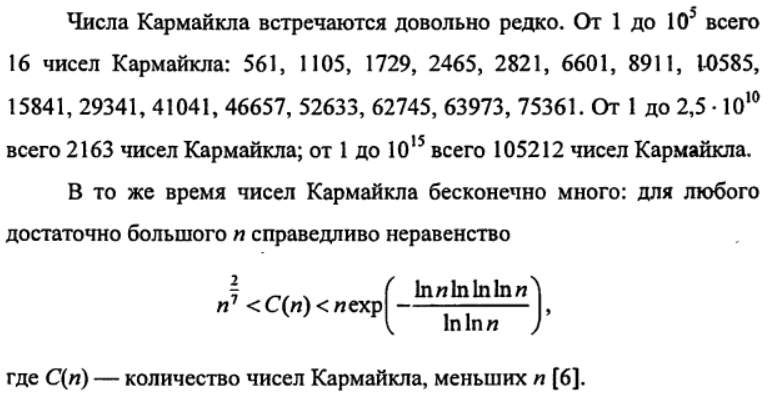

## 4.2. Теорема Люка: доказательство простоты

Источник: [1, §4.3, утверждение 4.38, с. 143; замечание 4.39, с. 143–144](#lit_1) — Menezes, van Oorschot, Vanstone, *Handbook of Applied Cryptography*.

**Критерий Люка.** Число $n\ge3$ простое тогда и только тогда, когда **существует** целое a, для которого
$$a^{n-1}\equiv1\pmod n,$$
но **для каждого** простого делителя q числа n−1 выполнено
$$a^{(n-1)/q}\not\equiv1\pmod n.$$

### Три возможных результата

| Результат функции | Что установлено |
|---|---|
| `"prime"` | Найдено основание, удовлетворяющее всем условиям: простота доказана. |
| `"composite"` | Обнаружен собственный делитель либо нарушено сравнение Ферма: составность доказана. |
| `"inconclusive"` | За t попыток свидетель простоты не найден; ни простота, ни составность этим не доказаны. |

Например, для n=7, a=2 первое сравнение выполняется, но $2^{(7-1)/2}=2^3\equiv1\pmod7$. Это основание не доказывает простоту 7, однако не доказывает и составность. Нужно попробовать другое a, например 3.

Замечание 4.39 предлагает повторять выбор основания. Ограничение числа попыток делает функцию конечной, но исчерпание попыток не является строгим доказательством составности.

### Задание 4.7. Тест Люка с ограничением числа попыток

Напишите `luk(n, t=10)` на основе [1, утверждение 4.38 и замечание 4.39](#lit_1).

1. Требуйте n≥2 и положительное целое t. Для n=2,3 сразу верните `"prime"`, для остальных чётных n — `"composite"`.
2. Один раз вычислите `D = decompose(n - 1)` из библиотеки курса.
3. Выполните до t попыток. Выберите основание a из 2..n−2. Если `gcd(a,n)>1`, верните `"composite"`. Если `mod_pow(a,n-1,n) != 1`, также верните `"composite"`.
4. Если для всех q из D выполнено `mod_pow(a,(n-1)//q,n) != 1`, верните `"prime"`. Иначе продолжите выбор оснований.
5. Если попытки исчерпаны, верните `"inconclusive"`.

Исследуйте n=7 и n=41041. Для 7 основание 2 не подтверждает простоту, а 3 доказывает простоту. Для 41041 возможны результаты `"composite"` и `"inconclusive"` в зависимости от оснований, но не `"prime"`. Объясните это с помощью свойства чисел Кармайкла.

**Смысл отрицательных проверок.** Неудача в проверках порядка означает переход к следующему основанию. Ветка `"composite"` допустима только при отдельном свидетельстве составности. Параметр t ограничивает число попыток.

In [12]:
# Ваше решение

def luk(n, t=10):
    """Критерий Люка с не более чем t основаниями.

    "prime" — простота доказана. "composite" — составность доказана.
    "inconclusive" — свидетель простоты за t попыток не найден.
    """
    if type(n) is not int or n < 2:
        raise ValueError("n должно быть целым >= 2")
    if type(t) is not int or t < 1:
        raise ValueError("t должно быть положительным целым")
    if n in (2, 3):
        return "prime"
    if n % 2 == 0:
        return "composite"
    # Полный список простых делителей n-1 нужен до выбора оснований и считается один раз.
    factors = decompose(n - 1)
    for _attempt in range(t):
        a = randint(2, n - 2)
        # Общий делитель или срыв сравнения Ферма доказывает составность.
        if gcd(a, n) > 1 or mod_pow(a, n - 1, n) != 1:
            return "composite"
        # Для каждого простого q | n-1 порядок не должен делить (n-1)/q.
        # Неудача здесь не доказывает составность: берём другое основание.
        proves_prime = True
        for q in factors:
            if mod_pow(a, (n - 1) // q, n) == 1:
                proves_prime = False
                break
        if proves_prime:
            return "prime"
    return "inconclusive"


assert luk(2) == "prime"
assert luk(3) == "prime"
assert luk(4) == "composite"
try:
    luk(1, 1)
    raise AssertionError("n < 2 должно быть отклонено")
except ValueError:
    pass
try:
    luk(7, 0)
    raise AssertionError("t = 0 должно быть отклонено")
except ValueError:
    pass

# Основание 2 для n=7 выполняет Ферма, но 2^3 ≡ 1 (mod 7): это не свидетель простоты.
assert mod_pow(2, 6, 7) == 1
assert mod_pow(2, 3, 7) == 1
# Основание 3 закрывает оба простых делителя 6.
assert mod_pow(3, 6, 7) == 1
assert mod_pow(3, 3, 7) != 1
assert mod_pow(3, 2, 7) != 1
# t большое, чтобы случайный перебор почти наверняка дошёл до 3 или 5.
assert luk(7, t=40) == "prime"

# У числа Кармайкла Ферма верна для всякого обратимого a, поэтому "prime" невозможна:
# иначе критерий Люка доказал бы простоту составного числа.
assert gcd(7, 41041) > 1
assert gcd(2, 41041) == 1 and mod_pow(2, 41040, 41041) == 1
assert any(mod_pow(2, 41040 // q, 41041) == 1 for q in decompose(41040))

seen = set()
for _trial in range(400):
    seen.add(luk(41041, t=10))
print("результаты luk(41041) за 400 вызовов:", seen)
assert "prime" not in seen
assert seen == {"composite", "inconclusive"}
print(
    "composite возникает на основании с общим делителем с 41041.\n"
    "Если все выбранные основания обратимы, порядок ни разу не подтверждается\n"
    "и функция возвращает inconclusive. prime для числа Кармайкла невозможен."
)


результаты luk(41041) за 400 вызовов: {'inconclusive', 'composite'}
composite возникает на основании с общим делителем с 41041.
Если все выбранные основания обратимы, порядок ни разу не подтверждается
и функция возвращает inconclusive. prime для числа Кармайкла невозможен.


**Вычислительное ограничение.** Критерий требует полного списка простых делителей n−1.

Эффективность зависит от доступности разложения n−1. Простота n и трудность разложения n−1 — разные вопросы; общей равной сложности здесь нет. В учебной `decompose` применяется пробное деление, поэтому случайное большое n может привести к непрактичному времени работы. Здесь используем небольшие примеры. Позже, при генерации p=2q+1, разложение p−1=2q известно заранее; для строгого применения критерия простота q также должна быть обоснована.

## 4.3. Тест Миллера—Рабина (Miller-Rabin primality test)

Источник: [1, §4.2.3, определение 4.21(ii), с. 139](#lit_1). Необходимое свойство нечётных простых чисел приведено перед ним в утверждении 4.20, с. 138.

**Утверждение** Пусть $n$ — нечётное простое число и
$$
n-1=2^s r,
$$
где $r$ нечётно. Пусть $a$ — любое целое число, для которого $\gcd(a,n)=1$. Тогда либо
$$
a^r\equiv1\pmod n,
$$
либо для некоторого целого $j$, $0\le j\le s-1$, выполняется
$$
a^{2^j r}\equiv-1\pmod n.
$$

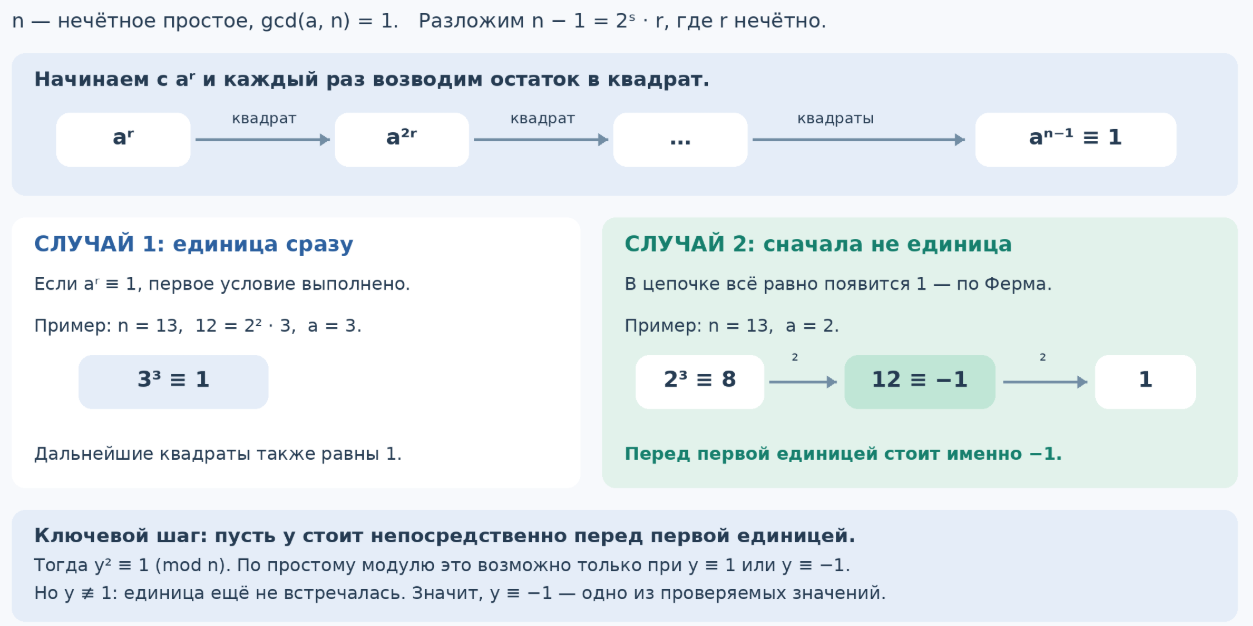

### Определение (сильная псевдопростота)

Пусть n — нечётное **составное** число,
$$n-1=2^s r,\qquad r\text{ нечётно},$$
и $1\le a\le n-1$. Число n называется **сильно (строго) псевдопростым по основанию a** (*strong pseudoprime to the base a*), если
$$a^r\equiv1\pmod n$$
или для некоторого целого j, $0\le j\le s-1$,
$$a^{2^j r}\equiv-1\pmod n.$$

Такое основание a называют **сильным лжецом** (*strong liar*) для n [1, определение 4.21(ii)]. Любое из этих сравнений обеспечивает $\gcd(a,n)=1$, поэтому отдельно включать взаимную простоту в условия определения не требуется.

**Важно.** Нечётное простое число также удовлетворяет указанному условию для каждого взаимно простого основания [1, утверждение 4.20]. Для него говорят о **прохождении сильного теста**, а термин «сильно псевдопростое» используют только для составного числа. Если простота или составность n ещё не установлена, прохождение одного раунда не позволяет назвать основание сильным лжецом.

### Пример
Число $3277 = 29 \cdot 113$ является *строго псевдопростым по основанию* 2.
Действительно, имеем $3276 = 2^2 \cdot 819$. Тогда
$$ 2^{819} \not \equiv \pm1 \pmod{3277},  2^{2\cdot819} \equiv -1 \pmod{3277}$$

### Задание 4.8

    
Найдите наименьшее *строго псевдопростое число* по основанию 2.

>2047

In [13]:
# Ваше решение

def passes_strong_test(n, a):
    """Сильный тест по одному основанию.

    True, если a^r ≡ 1 или a^{2^j r} ≡ -1 (mod n) для некоторого j < s.
    Для составного n такое a — сильный лжец. Для простого n то же сравнение
    выполнено, но число не называют псевдопростым.
    """
    # n-1 = 2^s * r, r нечётно.
    r = n - 1
    s = 0
    while r % 2 == 0:
        r //= 2
        s += 1
    y = mod_pow(a, r, n)
    if y == 1 or y == n - 1:
        return True
    for _step in range(s - 1):
        y = (y * y) % n
        if y == n - 1:
            return True
        # Квадрат дал 1, хотя предыдущий остаток не был ±1.
        if y == 1:
            return False
    return False


# Пример из текста: 3277 = 29*113, 3276 = 2^2 * 819, вторая степень уже равна -1.
assert mod_pow(2, 819, 3277) not in (1, 3276)
assert mod_pow(2, 2 * 819, 3277) == 3276
assert passes_strong_test(3277, 2) and not is_prime_fast(3277)

# Наименьшее нечётное составное, прошедшее сильный тест по основанию 2.
n = 9
while True:
    if passes_strong_test(n, 2) and not is_prime_fast(n):
        break
    n += 2

print("наименьшее строго псевдопростое по основанию 2:", n)
assert n == 2047
assert not is_prime_fast(2047)


наименьшее строго псевдопростое по основанию 2: 2047


### Определение. Сильный лжец

Если нечётное составное число проходит сильный тест по основанию $a$, это основание называют **сильным лжецом** для данного числа.

### Задание 4.9

    
Напишите функцию `strong_liar(n)`. С её помощью найдите все основания, при которых заданное нечётное составное число $n$ является строго псевдопростым. 

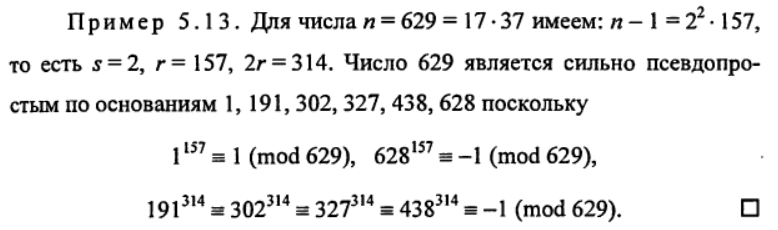 

Для $n=629$ вычислите долю сильных лжецов среди обратимых оснований.

In [14]:
# Ваше решение

def strong_liar(n):
    """Все сильные лжецы n среди оснований 1..n-1.

    Достаточно обратимых a: если степень сравнима с 1 или -1, gcd(a, n) = 1.
    Для простого n тот же список не называют лжецами.
    """
    return [a for a in range(1, n) if gcd(a, n) == 1 and passes_strong_test(n, a)]


liars_629 = strong_liar(629)
phi_629 = euler_phi(629)
print("сильные лжецы 629:", liars_629)
print(f"доля среди обратимых оснований: {len(liars_629)}/{phi_629}")
assert liars_629 == [1, 191, 302, 327, 438, 628]
assert phi_629 == 576
assert len(liars_629) * 96 == phi_629
print("6/576 = 1/96: сильных лжецов заметно меньше четверти группы.")


сильные лжецы 629: [1, 191, 302, 327, 438, 628]
доля среди обратимых оснований: 6/576
6/576 = 1/96: сильных лжецов заметно меньше четверти группы.


### Задание 4.10

    
Найдите в интервале от $8$ до $10000$ сильно псевдопростые числа по основанию $7$.

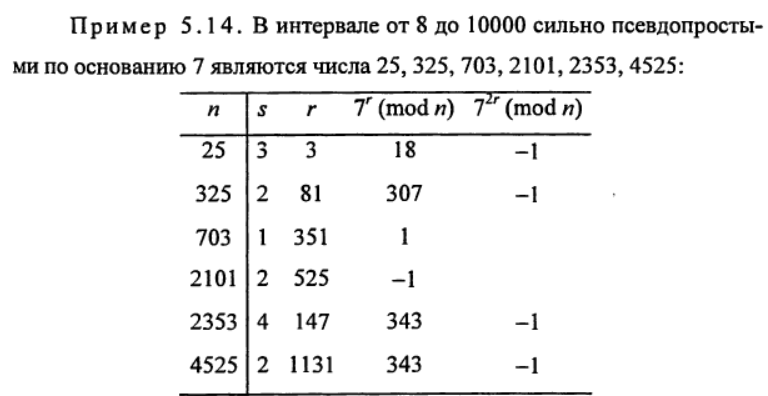

In [15]:
# Ваше решение

# Сильно псевдопростое по основанию 7: составное нечётное, прошедшее сильный тест.
# Полный список лжецов здесь не нужен, основание одно.
strong_base_7 = []
for n in range(9, 10001, 2):
    if passes_strong_test(n, 7) and not is_prime_fast(n):
        strong_base_7.append(n)

print("сильно псевдопростые по основанию 7 от 8 до 10000:")
print(strong_base_7)
assert strong_base_7 == [25, 325, 703, 2101, 2353, 4525]
print(
    "Список короче списка псевдопростых Ферма по тому же основанию:\n"
    "сильный тест отбрасывает часть чисел, которые проходят только сравнение Ферма."
)


сильно псевдопростые по основанию 7 от 8 до 10000:
[25, 325, 703, 2101, 2353, 4525]
Список короче списка псевдопростых Ферма по тому же основанию:
сильный тест отбрасывает часть чисел, которые проходят только сравнение Ферма.


### Задание 4.11. Две доли сильных лжецов

Для n=91 найдите всех сильных лжецов a в диапазоне $1\le a\le n-1$ с помощью `strong_liar(n)`. Обозначьте их количество L.

1. Вычислите долю $L/(n-1)$ **среди всех оснований** 1,...,n−1.
2. Вычислите долю $L/\varphi(n)$ **среди обратимых оснований**, то есть элементов $(\mathbb Z/n\mathbb Z)^*$; используйте библиотечную функцию `euler_phi`.
3. Сравните обе доли с 1/4 и объясните, почему значения различаются при одинаковом числителе.
4. Повторите вычисления для n=9. Какая доля превышает 1/4? Почему это не противоречит утверждению 4.23 Менезиса?

**Самопроверка.** Для 91: 20% среди всех оснований, 25% среди обратимых. Для 9: 25% и примерно 33,33% соответственно.

**Два пространства оснований.** Функция `strong_liar(n)` перебирает обратимые основания. Этого достаточно для полного списка сильных лжецов: любое из сравнений в определении сильной псевдопростоты обеспечивает $\gcd(a,n)=1$. Но долю можно считать с разными знаменателями: n−1 для всех оснований или $\varphi(n)$ для обратимых. Ни одна из этих долей не является автоматически вероятностью пропуска при выборе `randint(2,n-2)`: у этого диапазона другие границы.

In [16]:
# Ваше решение

def compare_fraction(numerator, denominator, bound_num, bound_den):
    """Сравнение дробей в целых: меньше, равно или больше."""
    left = numerator * bound_den
    right = denominator * bound_num
    if left < right:
        return "меньше"
    if left > right:
        return "больше"
    return "равно"


for n in (91, 9):
    liars = strong_liar(n)
    count = len(liars)
    phi = euler_phi(n)
    print(f"n={n}, сильные лжецы: {liars}")
    print(f"L = {count}, L/(n-1) = {count}/{n - 1}, L/φ(n) = {count}/{phi}")
    print(
        f"L/(n-1) {compare_fraction(count, n - 1, 1, 4)} 1/4; "
        f"L/φ(n) {compare_fraction(count, phi, 1, 4)} 1/4"
    )

# Самопроверка: 18/90 = 20%, 18/72 = 25%, 2/8 = 25%, 2/6 ≈ 33,33%.
assert len(strong_liar(91)) == 18
assert euler_phi(91) == 72
assert format_percent(18, 90) == "20,00%"
assert format_percent(18, 72) == "25,00%"
assert format_percent(2, 8) == "25,00%"
assert format_percent(2, 6) == "33,33%"
print(
    "Числитель один и тот же, а знаменатели нет: n-1 считает и необратимые основания,\n"
    "φ(n) — только группу. Необратимые основания сильными лжецами не бывают,\n"
    "поэтому первая доля меньше или равна второй.\n"
    "У 9 доля среди обратимых больше 1/4. Утверждение 4.23 как раз исключает n=9\n"
    "из оценки L ≤ φ(n)/4. Оценка L/(n-1) ≤ 1/4 для 9 по-прежнему верна, противоречия нет."
)


n=91, сильные лжецы: [1, 9, 10, 12, 16, 17, 22, 29, 38, 53, 62, 69, 74, 75, 79, 81, 82, 90]
L = 18, L/(n-1) = 18/90, L/φ(n) = 18/72
L/(n-1) меньше 1/4; L/φ(n) равно 1/4
n=9, сильные лжецы: [1, 8]
L = 2, L/(n-1) = 2/8, L/φ(n) = 2/6
L/(n-1) равно 1/4; L/φ(n) больше 1/4
Числитель один и тот же, а знаменатели нет: n-1 считает и необратимые основания,
φ(n) — только группу. Необратимые основания сильными лжецами не бывают,
поэтому первая доля меньше или равна второй.
У 9 доля среди обратимых больше 1/4. Утверждение 4.23 как раз исключает n=9
из оценки L ≤ φ(n)/4. Оценка L/(n-1) ≤ 1/4 для 9 по-прежнему верна, противоречия нет.


### Утверждение 4.23 из источника [1]. Число сильных лжецов

Источник: [1, §4.2.3, утверждение 4.23, с. 139](#lit_1) — Menezes, van Oorschot, Vanstone, *Handbook of Applied Cryptography*.

Пусть n — нечётное составное число, а L — число его сильных лжецов среди оснований $1\le a\le n-1$. Тогда
$$\boxed{\frac{L}{n-1}\le\frac14.}$$
Более того, если $n\ne9$, то
$$\boxed{L\le\frac{\varphi(n)}4,\qquad\frac{L}{\varphi(n)}\le\frac14.}$$

**Исключение n=9 относится только ко второй оценке.** Для 9 сильные лжецы — 1 и 8, поэтому
$$\frac{L}{n-1}=\frac28=\frac14,\qquad
\frac{L}{\varphi(n)}=\frac26=\frac13>\frac14.$$
Первая оценка выполняется и для 9. Если n простое, утверждение о доле лжецов к нему не применяется.

### Задание 4.12

Найдите наименьшее нечётное составное число $n>91$, для которого число сильных лжецов равно $\varphi(n)/4$. Перебирайте кандидатов по возрастанию и проверяйте равенство в целых числах.

In [17]:
# Ваше решение

# Ищем наименьшее нечётное составное n > 91 с равенством 4*L = φ(n), без перевода в float.
n = 93
while True:
    if not is_prime_fast(n):
        count = len(strong_liar(n))
        phi = euler_phi(n)
        if 4 * count == phi:
            break
    n += 2

print(f"n = {n}, L = {count}, φ(n) = {phi}, 4*L = {4 * count}")
assert n == 703
assert 4 * count == phi
print("Равенство выполнено в целых: число сильных лжецов ровно четверть группы.")


n = 703, L = 162, φ(n) = 648, 4*L = 648
Равенство выполнено в целых: число сильных лжецов ровно четверть группы.


### Замечание
Для большинства нечётных составных n число сильных лжецов существенно меньше оценки $\varphi(n)/4$ [1, замечание 4.26, с. 140]. При использовании этой верхней границы сохраняем оговорку **n≠9** из утверждения 4.23. Оценка L/(n−1)≤1/4 относится ко всем нечётным составным n.

### Определение. Сильный свидетель составности

Пусть $n\ge3$ нечётно, $n-1=2^s r$, где $r$ нечётно, и $1\le a<n$. Основание $a$ доказывает составность $n$, если $a^r\not\equiv1\pmod n$ и для **всех** $j=0,\ldots,s-1$ выполняется $a^{2^jr}\not\equiv-1\pmod n$.

<a id='alg1'></a>

### 4.3.1. Тест Миллера—Рабина: цепочка последовательных квадратов

Если для выбранного основания $a$ условия сильного теста не выполнены, то $a$ — **свидетель составности**, и число $n$ точно составное.

Если условия выполнены, говорят, что **число $n$ прошло сильный тест по основанию $a$**. Такой результат возможен как для простого, так и для составного числа.

Только если $n$ составное, прошедшее проверку основание $a$ называют **сильным лжецом**, а число $n$ — **сильно псевдопростым по основанию $a$**.

Для повышения надёжности тест повторяют с независимо выбранными случайными основаниями. Прохождение всех проверок не является доказательством простоты.

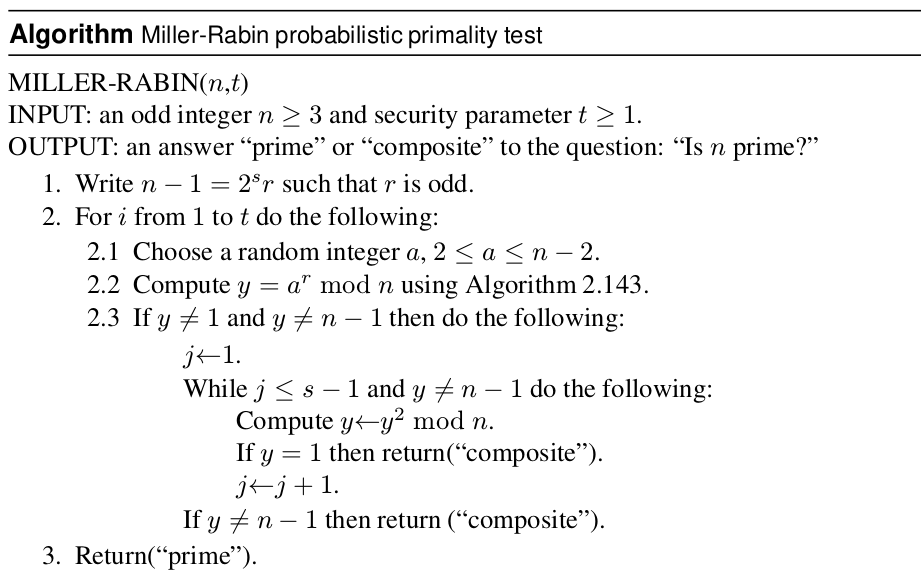

Реализуйте `miller_rabin(n, t)` по алгоритму 4.24 источника [1]. Для положительного целого $t$ выполните до $t$ независимых раундов с основаниями от 2 до $n-2$. Обработайте $n<2$, числа 2 и 3, остальные чётные числа и недопустимые значения $t$.

In [18]:
# Ваше решение

def miller_rabin(n, t):
    """Алгоритм 4.24. False доказывает составность. True — t раундов пройдены, простота не доказана."""
    if type(t) is not int or t < 1:
        raise ValueError("t должно быть положительным целым")
    if n < 2:
        return False
    # Для 2 и 3 выбирать основание из 2..n-2 нельзя: интервал пуст.
    if n in (2, 3):
        return True
    if n % 2 == 0:
        return False
    # n-1 = 2^s * r пишем один раз: от основания разложение не зависит.
    r = n - 1
    s = 0
    while r % 2 == 0:
        r //= 2
        s += 1
    for _round in range(t):
        a = randint(2, n - 2)
        y = mod_pow(a, r, n)
        if y == 1 or y == n - 1:
            continue
        witness = True
        for _step in range(s - 1):
            y = (y * y) % n
            if y == n - 1:
                witness = False
                break
            # Нетривиальный квадратный корень из 1 доказывает составность сразу.
            if y == 1:
                return False
        if witness:
            return False
    return True


assert miller_rabin(2, 1) is True
assert miller_rabin(3, 1) is True
assert miller_rabin(0, 1) is False
assert miller_rabin(1, 1) is False
assert miller_rabin(4, 1) is False
assert miller_rabin(5, 5) is True
# У 9 и 105 в диапазоне 2..n-2 сильных лжецов нет: уже один раунд отвергает число.
assert miller_rabin(9, 1) is False
assert miller_rabin(105, 1) is False
try:
    miller_rabin(11, 0)
    raise AssertionError("t = 0 должно быть отклонено")
except ValueError:
    pass
print(
    "True после t раундов не доказывает простоту: основания могли оказаться сильными лжецами.\n"
    "False доказывает составность, потому что нарушено необходимое свойство нечётного простого."
)


True после t раундов не доказывает простоту: основания могли оказаться сильными лжецами.
False доказывает составность, потому что нарушено необходимое свойство нечётного простого.


Если при возведении в квадрат остатка, отличного от $1$ и $-1$ по данному модулю, получена единица, модуль составной.

### Задание 4.13

Сравните `miller_rabin(n, 50)` с точной проверкой `is_prime_fast(n)` для всех целых чисел от −5 до 1000. Проверьте и принятие простых, и отклонение составных. Объясните, какие выводы можно сделать по одному эксперименту.

In [19]:
# Ваше решение

# Сравниваем вероятностный тест с точным перебором делителей на всём отрезке.
mismatches = [
    n for n in range(-5, 1001) if miller_rabin(n, 50) != is_prime_fast(n)
]
print("расхождений miller_rabin(n, 50) и is_prime_fast на -5..1000:", len(mismatches))
assert not mismatches
print(
    "На этом отрезке совпали и принятие простых, и отклонение составных.\n"
    "Один конечный эксперимент реализацию поддерживает, но оценку 4^{-50} не доказывает:\n"
    "он не охватывает все составные числа. Совпадение ожидаемо: наименьшее строго\n"
    "псевдопростое по основанию 2 равно 2047, а 50 случайных оснований делают пропуск\n"
    "составного на этом отрезке практически невероятным."
)


расхождений miller_rabin(n, 50) и is_prime_fast на -5..1000: 0
На этом отрезке совпали и принятие простых, и отклонение составных.
Один конечный эксперимент реализацию поддерживает, но оценку 4^{-50} не доказывает:
он не охватывает все составные числа. Совпадение ожидаемо: наименьшее строго
псевдопростое по основанию 2 равно 2047, а 50 случайных оснований делают пропуск
составного на этом отрезке практически невероятным.


### Задание 4.14

Проверьте, что число $91$ не является простым. 
Уберите случайный выбор оснований в функции `miller_rabin(n,t)`. Сделайте так, что всегда выбираются строгие лжецы (см. задание 4.11). Какой ответ дает функция?

In [20]:
# Ваше решение

assert is_prime_fast(91) is False
liars_in_range = [a for a in strong_liar(91) if 2 <= a <= 89]
print("сильные лжецы 91 в диапазоне выбора 2..89:", liars_in_range)
assert liars_in_range


def miller_rabin_on_liars(n, t):
    """Тот же сильный тест, но основание всегда один и тот же сильный лжец.

    Случайный randint убран специально для этого опыта. Рабочая miller_rabin
    выше остаётся со случайными основаниями: её ещё вызывают следующие задания.
    """
    a = min(candidate for candidate in strong_liar(n) if 2 <= candidate <= n - 2)
    r = n - 1
    s = 0
    while r % 2 == 0:
        r //= 2
        s += 1
    for _round in range(t):
        y = mod_pow(a, r, n)
        if y == 1 or y == n - 1:
            continue
        witness = True
        for _step in range(s - 1):
            y = (y * y) % n
            if y == n - 1:
                witness = False
                break
            if y == 1:
                return False
        if witness:
            return False
    return True


answer = miller_rabin_on_liars(91, 50)
print("miller_rabin по сильным лжецам 91 возвращает", answer)
assert answer is True
print(
    "Функция отвечает True, хотя 91 составное.\n"
    "Оценка ошибки предполагает, что основание выбирают случайно.\n"
    "Если каждый раунд берёт сильного лжеца, составное число проходит все проверки."
)


сильные лжецы 91 в диапазоне выбора 2..89: [9, 10, 12, 16, 17, 22, 29, 38, 53, 62, 69, 74, 75, 79, 81, 82]
miller_rabin по сильным лжецам 91 возвращает True
Функция отвечает True, хотя 91 составное.
Оценка ошибки предполагает, что основание выбирают случайно.
Если каждый раунд берёт сильного лжеца, составное число проходит все проверки.


### Вероятность пропуска составного числа

Источник: [1, §4.2.3, утверждение 4.25, замечание 4.26 и пример 4.27, с. 140](#lit_1) — Menezes, van Oorschot, Vanstone, *Handbook of Applied Cryptography*.

**Утверждение 4.25 из источника [1].** Для любого **фиксированного нечётного составного** числа n вероятность того, что тест Миллера—Рабина после t раундов вернёт положительный ответ, меньше
$$\boxed{4^{-t}=\left(\frac14\right)^t.}$$

Здесь t≥1 — фактическое число раундов, которые число должно пройти. В каждом раунде основание выбирается **независимо и равномерно** среди целых чисел $2\le a\le n-2$, как в алгоритме 4.24 источника [1]. Повторение основания возможно; требовать, чтобы все основания были различны, не нужно. При обнаружении свидетеля составности тест завершается раньше с отрицательным ответом.

**Почему появляется степень t?** Если доля сильных лжецов в используемом диапазоне равна P, то вероятность выбрать только лжецов в t независимых раундах равна $P^t$. Утверждение 4.23 ограничивает долю лжецов среди всех оснований 1..n−1. Исключение тривиальных лжецов 1 и n−1 уменьшает долю; для диапазона 2..n−2 она строго меньше 1/4. Поэтому $P^t<4^{-t}$.

Например, для 50 раундов
$$4^{-50}=2^{-100}\approx7{,}89\cdot10^{-31}<10^{-30}.$$
Это граница вероятности **пропустить заданное составное число** при случайном выборе оснований. Она не зависит от того, сколько цифр у этого числа.

**Не путать направления условной вероятности.** Мы рассматриваем
$$\Pr(\text{тест пройден}\mid\text{заданный кандидат составной}),$$
а не
$$\Pr(\text{кандидат составной}\mid\text{тест пройден}).$$
Для второй величины требуется модель выбора кандидатов и сведения о частоте простых среди них.

**Замечание 4.26.** Для большинства составных чисел сильных лжецов намного меньше допускаемой верхней границы, поэтому фактическая вероятность пропуска существенно ниже $4^{-t}$.

**Пример 4.27: n=105=3·5·7.** Среди оснований 1..104 сильные лжецы только 1 и 104. В диапазоне выбора 2..103 их нет: любой выбранный кандидат a обнаруживает составность уже в первом раунде. Аналогичное свойство выполняется для произведения первых k нечётных простых при k≥2 [1, пример 4.27].

Напишите функцию `mr_error_bound(t)`, которая возвращает точную границу в виде дроби при целом положительном $t$.

In [21]:
# Ваше решение

from fractions import Fraction


def mr_error_bound(t):
    """Точная граница 4^{-t} вероятности пропустить фиксированное нечётное составное число."""
    if type(t) is not int or t < 1:
        raise ValueError("t должно быть положительным целым")
    return Fraction(1, 4**t)


assert mr_error_bound(1) == Fraction(1, 4)
assert mr_error_bound(2) == Fraction(1, 16)
print("граница одного раунда:", mr_error_bound(1))
print("граница двух раундов:", mr_error_bound(2))


граница одного раунда: 1/4
граница двух раундов: 1/16


**Вычисление границы.** Найдите границу вероятности пропуска фиксированного нечётного составного числа за 50 раундов. Затем проверьте список сильных лжецов для 105 и объясните, почему в этом примере фактическая вероятность пропуска равна нулю.

In [22]:
# Ваше решение

bound = mr_error_bound(50)
# 4^50 = 2^100. С 10^30 сравниваем знаменатели в целых, без приближения float.
print("граница 50 раундов:", bound)
print("4^50 > 10^30:", 4**50 > 10**30)
assert bound == Fraction(1, 4**50)
assert 4**50 > 10**30

liars_105 = strong_liar(105)
in_draw = [a for a in liars_105 if 2 <= a <= 103]
print("сильные лжецы 105:", liars_105)
print("из них в диапазоне выбора 2..103:", in_draw)
assert liars_105 == [1, 104]
assert in_draw == []
print(
    "Граница 50 раундов меньше 10^{-30}, потому что знаменатель 4^50 больше 10^30.\n"
    "Для 105 в диапазоне 2..103 сильных лжецов нет: любое выбранное основание\n"
    "уже в первом раунде доказывает составность, и фактическая вероятность пропуска равна нулю.\n"
    "Оценка 4^{-t} здесь не достигается."
)


граница 50 раундов: 1/1267650600228229401496703205376
4^50 > 10^30: True
сильные лжецы 105: [1, 104]
из них в диапазоне выбора 2..103: []
Граница 50 раундов меньше 10^{-30}, потому что знаменатель 4^50 больше 10^30.
Для 105 в диапазоне 2..103 сильных лжецов нет: любое выбранное основание
уже в первом раунде доказывает составность, и фактическая вероятность пропуска равна нулю.
Оценка 4^{-t} здесь не достигается.


### Задание 4.15

Напишите `is_prime_mr(n, t=50)`. Проверьте, что $t$ — положительное целое число. Обработайте $n<2$, затем проверьте совпадение с малыми простыми из `primes(997)` и делимость на них. Для оставшихся кандидатов вызовите `miller_rabin(n, t)`. Проверьте числа 1000000000061 и 1000000000063. Объясните смысл положительного ответа этой версии функции.

In [23]:
# Ваше решение

def is_prime_mr(n, t=50):
    """Пробное деление на простые до 997 и затем miller_rabin.

    True этой версии не доказывает простоту: случайные раунды могли пропустить составное.
    """
    if type(t) is not int or t < 1:
        raise ValueError("t должно быть положительным целым")
    if n < 2:
        return False
    for prime in primes(997):
        if n == prime:
            return True
        # Собственный делитель из этого списка доказывает составность без раундов.
        if n % prime == 0:
            return False
    return miller_rabin(n, t)


assert is_prime_mr(2) is True
assert is_prime_mr(1) is False
assert is_prime_mr(4) is False
for number in (1000000000061, 1000000000063):
    verdict = is_prime_mr(number)
    print(number, verdict)
    # Оба числа простые, поэтому сильный тест по случайному основанию их не отвергает.
    assert verdict is True
print(
    "Положительный ответ значит: простого делителя <= 997 нет и все t раундов пройдены.\n"
    "Для фиксированного составного вероятность такого ответа меньше 4^{-t}.\n"
    "Это ещё не доказательство простоты."
)


1000000000061 True
1000000000063 True
Положительный ответ значит: простого делителя <= 997 нет и все t раундов пройдены.
Для фиксированного составного вероятность такого ответа меньше 4^{-t}.
Это ещё не доказательство простоты.


Тест Миллера—Рабина опирается на два свойства нечётного простого числа $p$:

1. **Малая теорема Ферма:** для любого $a$, взаимно простого с $p$,
   $$
   a^{p-1}\equiv1\pmod p.
   $$

2. **Отсутствие нетривиальных квадратных корней из единицы:** если
   $$
   x^2\equiv1\pmod p,
   $$
   то $x\equiv1\pmod p$ или $x\equiv-1\pmod p$.

Поэтому составность проверяемого нечётного числа $n$ можно доказать, обнаружив нарушение сравнения Ферма для взаимно простого основания или остаток $x\not\equiv\pm1\pmod n$, квадрат которого сравним с единицей.

Тест Миллера—Рабина выявляет такие нарушения с помощью возведения в степень и последовательного вычисления квадратов по модулю $n$.

### Задание 4.16

    
Найдите пять наименьших нечётных составных чисел, которые являются [<span style="color: #3498db;font-weight: bold;">строго псевдопростыми по основанию $2$</span>](https://en.wikipedia.org/wiki/Strong_pseudoprime).
Переберите числа до 10000.

Справочная страница: [9](#lit_9).

In [24]:
# Ваше решение

# Пять наименьших нечётных составных, строго псевдопростых по основанию 2.
# Перебор идёт до 10000, простые тест тоже проходят, поэтому составность проверяем отдельно.
strong_base_2 = []
for n in range(9, 10001, 2):
    if passes_strong_test(n, 2) and not is_prime_fast(n):
        strong_base_2.append(n)

five = strong_base_2[:5]
print("пять наименьших:", five)
print("все до 10000:", strong_base_2)
assert five == [2047, 3277, 4033, 4681, 8321]
print("Первое из них — ψ1 = 2047.")


пять наименьших: [2047, 3277, 4033, 4681, 8321]
все до 10000: [2047, 3277, 4033, 4681, 8321]
Первое из них — ψ1 = 2047.


### Задание 4.17

    
Найдите наименьшее нечётное составное число, которое является строго псевдопростым по основаниям $2$ и $3$.
Переберите числа до 2000000.

In [25]:
# Ваше решение

# ψ2 — наименьшее нечётное составное, сильно псевдопростое сразу по основаниям 2 и 3.
print("перебор до 2_000_000")
found = None
n = 9
while n < 2_000_000:
    if (
        passes_strong_test(n, 2)
        and passes_strong_test(n, 3)
        and not is_prime_fast(n)
    ):
        found = n
        break
    n += 2

print("ψ2 =", found)
assert found == 1_373_653


перебор до 2_000_000
ψ2 = 1373653


### Задание 4.18

    
Найдите наименьшее нечётное составное число, которое является строго псевдопростым по основаниям $2$, $3$ и $5$. Переберите числа до 30 000 000.

In [26]:
# Ваше решение

# ψ3 — наименьшее нечётное составное, сильно псевдопростое по основаниям 2, 3 и 5.
# Простые тоже проходят эти проверки, поэтому составность смотрим отдельно.
print("перебор до 30_000_000")
found = None
n = 9
while n < 30_000_000:
    if (
        passes_strong_test(n, 2)
        and passes_strong_test(n, 3)
        and passes_strong_test(n, 5)
        and not is_prime_fast(n)
    ):
        found = n
        break
    n += 2

print("ψ3 =", found)
assert found == 25_326_001


перебор до 30_000_000
ψ3 = 25326001


### Определение ($\psi_t$)
>Пусть $p_1, p_2, \ldots, p_t$ первые $t$ простых чисел. Определим $\psi_t$ как наименьшее положительное составное целое число, которое является строго псевдопростым для оснований $p_1, p_2, \ldots, p_t$.

Согласно определению в предыдущих заданиях были найдены $\psi_1$, $\psi_2$ и $\psi_3$.

### Фиксированные основания и детерминированная проверка

Пусть $\psi_t$ — наименьшее нечётное составное число, проходящее сильный тест по каждому из первых $t$ простых оснований.

Тогда для нечётного $n<\psi_t$ прохождение проверок по всем этим основаниям доказывает простоту. Составного числа, проходящего весь набор проверок в этом диапазоне, нет по определению $\psi_t$.

Таким образом, **фиксированный набор оснований вместе с установленным порогом даёт детерминированный тест простоты в указанном диапазоне**. За пределами диапазона положительный результат уже не гарантирует простоту.

Источник определения и первых восьми значений: [1, определение 4.29 и таблица 4.1, с. 140](#lit_1).

| Строгая верхняя граница для $n$ | Основания, которые нужно проверить |
|---:|---|
| $2\,047$ | $2$ |
| $1\,373\,653$ | $2,3$ |
| $25\,326\,001$ | $2,3,5$ |
| $3\,215\,031\,751$ | $2,3,5,7$ |
| $2\,152\,302\,898\,747$ | $2,3,5,7,11$ |
| $3\,474\,749\,660\,383$ | $2,3,5,7,11,13$ |
| $341\,550\,071\,728\,321$ | $2,3,5,7,11,13,17$ |
| $341\,550\,071\,728\,321$ | $2,3,5,7,11,13,17,19$ |
| $3\,825\,123\,056\,546\,413\,051$ | $2,3,5,7,11,13,17,19,23$ |

Последняя строка — результат Jiang и Deng: [8, Strong pseudoprimes to the first 9 prime bases](#lit_8).

**Граница строгая:** требуется $n<\psi_t$. Само число $\psi_t$ составное, но проходит все указанные проверки.

**Обработка малых чисел.** Перед проверками:
- $n<2$ отвергаем;
- если $n$ совпадает с одним из простых оснований выбранного набора, принимаем его как простое;
- остальные чётные числа отвергаем.

После этого все основания набора взаимно просты с простым кандидатом, и можно применять сильный тест без ошибочного отклонения случая $a=n$.

**Пример.** Для нечётного $n<2047$ достаточно основания $2$. Однако $2047=23\cdot89$ проходит эту проверку, поэтому включать границу в диапазон нельзя.

Эксперимент на небольшом диапазоне проверяет реализацию, но не доказывает справедливость табличных порогов. Их обоснование берётся из указанных источников.

### Задание 4.19 (miller_rabin_det)

    
Напишите функцию `miller_rabin_det(n, s, r, a)`, выполняющую **один раунд сильного теста Миллера—Рабина по заданному основанию** $a$.

Предусловия: $n\ge5$ — нечётное число, $n-1=2^s r$, где $r$ нечётно, и $2\le a\le n-2$.

Функция должна возвращать:
- `False`, если основание $a$ обнаруживает составность $n$;
- `True`, если число $n$ прошло проверку по основанию $a$.

Основание передаётся явно, случайный выбор не используется. Положительный результат одного раунда **не доказывает простоту**. Детерминированный тест простоты получается при проверке установленного набора оснований в соответствующем диапазоне $n$.

In [27]:
# Ваше решение

def miller_rabin_det(n, s, r, a):
    """Один сильный раунд по заданным s, r и основанию a.

    False — a доказывает составность. True — раунд пройден, простота не доказана.
    Предусловие вызывающего кода: нечётное n >= 5, n-1 = 2^s * r, r нечётно, 2 <= a <= n-2.
    """
    y = mod_pow(a, r, n)
    if y == 1 or y == n - 1:
        return True
    for _step in range(s - 1):
        y = (y * y) % n
        if y == n - 1:
            return True
        if y == 1:
            return False
    return False


def split_odd_part(number):
    """number = 2^s * r с нечётным r. Для сильного теста number = n - 1."""
    s = 0
    r = number
    while r % 2 == 0:
        r //= 2
        s += 1
    return s, r


# Раунд по явному основанию совпадает с определением сильной псевдопростоты.
for modulus, base in ((91, 2), (91, 9), (2047, 2), (105, 2), (3277, 2)):
    s, r = split_odd_part(modulus - 1)
    assert miller_rabin_det(modulus, s, r, base) is passes_strong_test(modulus, base)

s, r = split_odd_part(2046)
assert miller_rabin_det(2047, s, r, 2) is True
print(
    "2047 проходит раунд по основанию 2, хотя составное.\n"
    "Один True простоту не доказывает. Детерминированный тест получается,\n"
    "когда пройден весь установленный набор оснований и n лежит ниже известного порога."
)


2047 проходит раунд по основанию 2, хотя составное.
Один True простоту не доказывает. Детерминированный тест получается,
когда пройден весь установленный набор оснований и n лежит ниже известного порога.


### Задание 4.20 (is_prime_mr продолжение)

Добавьте в функцию `is_prime_mr(n,t)` для чисел $n<2^{64}$ вызов детерминированного теста Миллера—Рабина.  
Найдите с помощью этой функции простые числа из интервала $[3825123056546412851,3825123056546413051)$.
Проверьте полученные значения с помощью [<span style="color: #3498db;font-weight: bold;">isprime</span>](https://docs.sympy.org/latest/modules/ntheory.html#sympy.ntheory.primetest.isprime):

``` python
from sympy import isprime
```
Для полного набора первых 12 простых оснований при n<2^64 используем результат о ψ12 из [5, теорема 1.1](#lit_5).

Документация функции: [6](#lit_6).

In [28]:
# Ваше решение

from sympy import isprime

# Простые до 997 не зависят от кандидата. Повторное решето на каждом вызове ответ не меняет.
_TRIAL_PRIMES = primes(997)
# Первые 12 простых. Для нечётного n < 2^64 прохождение всех этих оснований доказывает простоту:
# ψ_12 > 2^64. Само 2^64 чётное и отсекается делением на 2.
_MR_BASES = (2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37)
_MR_LIMIT = 2**64


def is_prime_mr(n, t=50):
    """Пробное деление, затем детерминированный сильный тест ниже 2^64 и случайные раунды выше.

    Ниже 2^64 параметр t на ответ не влияет, но по контракту всё равно проверяется.
    Выше границы True означает только, что t случайных раундов пройдены.
    """
    if type(t) is not int or t < 1:
        raise ValueError("t должно быть положительным целым")
    if n < 2:
        return False
    for prime in _TRIAL_PRIMES:
        if n == prime:
            return True
        if n % prime == 0:
            return False
    if n < _MR_LIMIT:
        s, r = split_odd_part(n - 1)
        for a in _MR_BASES:
            # Основания меньше 997, а кандидат после пробного деления больше, поэтому a <= n-2.
            if not miller_rabin_det(n, s, r, a):
                return False
        return True
    return miller_rabin(n, t)


# 25 326 001 = 2251*11251. Оба множителя больше 997, отсев их не видит.
# Число проходит основания 2, 3, 5 и должно отсеяться уже основанием 7 из полного набора.
assert passes_strong_test(25_326_001, 2) is True
assert is_prime_mr(25_326_001) is False
assert is_prime_mr(2047) is False
assert is_prime_mr(1000000000061) is True
assert is_prime_mr(1000000000063) is True

lo = 3825123056546412851
hi = 3825123056546413051
found = [n for n in range(lo, hi) if is_prime_mr(n)]
checked = [n for n in range(lo, hi) if isprime(n)]
print("простые в интервале:", found)
assert found == checked
print(
    "Все найденные числа меньше 2^64, поэтому положительный ответ is_prime_mr\n"
    "здесь доказывает простоту: пройден полный набор первых 12 простых оснований.\n"
    "sympy.isprime на этом же интервале даёт тот же список."
)


простые в интервале: [3825123056546412853, 3825123056546412931, 3825123056546412941, 3825123056546412979]
Все найденные числа меньше 2^64, поэтому положительный ответ is_prime_mr
здесь доказывает простоту: пройден полный набор первых 12 простых оснований.
sympy.isprime на этом же интервале даёт тот же список.


### Задание 4.21

    
Известно, что в последовательности $1001!+2, 1001!+3, \ldots, 1001!+1001$ нет ни одного простого числа. Этот пример
является иллюстрацией того, что последовательные интервалы между простыми числами могут быть сколь угодно длинными.
С помощью функции `is_prime_mr(n,t)` убедитесь в этом.

In [29]:
# Ваше решение

# 1001! + k делится на k при 2 <= k <= 1001. Составное k делится на простое <= 31,
# и это простое тоже делит 1001! + k. Пробное деление is_prime_mr такой делитель видит.
factorial = 1
for k in range(2, 1002):
    factorial *= k

for k in range(2, 1002):
    if is_prime_mr(factorial + k):
        raise AssertionError(k)

print("среди 1001!+2, ..., 1001!+1001 простых нет: длина промежутка без простых не меньше 1000")
print(
    "Тот же приём с n! даёт промежуток без простых длины n-1. Промежутки могут быть сколь угодно длинными.\n"
    "is_prime_mr отвергает эти числа уже на малом простом делителе, раунды Миллера—Рабина не нужны."
)


среди 1001!+2, ..., 1001!+1001 простых нет: длина промежутка без простых не меньше 1000
Тот же приём с n! даёт промежуток без простых длины n-1. Промежутки могут быть сколь угодно длинными.
is_prime_mr отвергает эти числа уже на малом простом делителе, раунды Миллера—Рабина не нужны.


### 4.3.2. Тест Миллера—Рабина: двоичное возведение в степень слева направо
Источник этой организации проверки: [7, §33.8, процедура WITNESS](#lit_7). В книге `True` означает найденного свидетеля составности, а в нашей `Miller_Rabin` — прохождение проверки.

Напомним следующее утверждение:
### Утверждение. Квадратные корни из единицы по простому модулю
>Если $p$ является нечётным простым числом, то уравнение $$x^2 \equiv 1 \pmod{p}$$  
имеет ровно два решения: $x \equiv 1$ и $x \equiv -1 \pmod{p}$.

Мы видели, как используется это свойство в [первой реализации теста Миллера—Рабина (§4.3.1)](#alg1).
Посмотрим теперь, как можно использовать быстрый алгоритм возведения в степень по модулю и это утверждение для теста на простоту.

Возьмём число Кармайкла $561$ и вычислим $$2^{560} \pmod{561} $$

In [30]:
# Ваше решение

# 561 — число Кармайкла, поэтому сравнение Ферма по основанию 2 выполняется.
remainder = mod_pow(2, 560, 561)
print(f"2^560 mod 561 = {remainder}")
assert remainder == 1
print("Малая теорема Ферма здесь выполняется, хотя 561 = 3*11*17 составное.")


2^560 mod 561 = 1
Малая теорема Ферма здесь выполняется, хотя 561 = 3*11*17 составное.


Малая теорема Ферма выполняется, хотя число $561$ не является простым.
Применим для вычисления указанной степени алгоритм быстрого возведения слева направо с выводом промежуточных результатов:

In [31]:
# Ваше решение

# Слева направо по битам показателя 560. Печатаем остаток до каждого квадрата,
# чтобы увидеть нетривиальный корень из единицы.
n = 561
b = 2
e = n - 1
A = 1
print(f"биты {e}: {bin(e)}")
for i in range(e.bit_length() - 1, -1, -1):
    S = (A * A) % n
    nontrivial = S == 1 and A != 1 and A != n - 1
    print(f"i={i}: A={A}, A^2 mod 561={S}, бит={(e >> i) & 1}, нетривиальный корень={nontrivial}")
    if nontrivial:
        print(f"{A}^2 ≡ 1 (mod 561), но {A} не сравнимо ни с 1, ни с -1.")
        break
    A = S
    if (e >> i) & 1:
        A = (A * b) % n

assert nontrivial and A == 67
print("Корень 67 доказывает составность 561, хотя итоговое сравнение Ферма выполнено.")


биты 560: 0b1000110000
i=9: A=1, A^2 mod 561=1, бит=1, нетривиальный корень=False
i=8: A=2, A^2 mod 561=4, бит=0, нетривиальный корень=False
i=7: A=4, A^2 mod 561=16, бит=0, нетривиальный корень=False
i=6: A=16, A^2 mod 561=256, бит=0, нетривиальный корень=False
i=5: A=256, A^2 mod 561=460, бит=1, нетривиальный корень=False
i=4: A=359, A^2 mod 561=412, бит=1, нетривиальный корень=False
i=3: A=263, A^2 mod 561=166, бит=0, нетривиальный корень=False
i=2: A=166, A^2 mod 561=67, бит=0, нетривиальный корень=False
i=1: A=67, A^2 mod 561=1, бит=0, нетривиальный корень=True
67^2 ≡ 1 (mod 561), но 67 не сравнимо ни с 1, ни с -1.
Корень 67 доказывает составность 561, хотя итоговое сравнение Ферма выполнено.


В процессе вычислений получено
$$
67^2\equiv1\pmod{561},
$$
причём $67\not\equiv1\pmod{561}$ и $67\not\equiv-1\pmod{561}$.

Таким образом, 67 — **нетривиальный квадратный корень из единицы** по модулю 561. По нечётному простому модулю таких корней нет: из $x^2\equiv1$ следует $x\equiv\pm1$. Поэтому **561 — составное число**.

Это свойство можно использовать при вычислении $b^{n-1}\bmod n$ методом последовательных возведений в квадрат. Пусть $n$ нечётно и $\gcd(b,n)=1$. Составность $n$ доказана, если:

1. На каком-либо шаге возведения в квадрат получено
   $$
   x^2\equiv1\pmod n,
   $$
   хотя предыдущее значение $x\not\equiv\pm1\pmod n$.
2. Либо окончательный результат нарушает малую теорему Ферма:
   $$
   b^{n-1}\not\equiv1\pmod n.
   $$

**Само по себе появление единицы до окончания вычислений не доказывает составность.** Важно, какое значение стояло перед ней: составность обнаруживается при возведении в квадрат остатка, отличного от $1$ и $-1$.

Если ни одно нарушение не обнаружено, проверка по основанию $b$ пройдена, но простота $n$ ещё не доказана.

Напомним алгоритм возведения в степень слева направо:

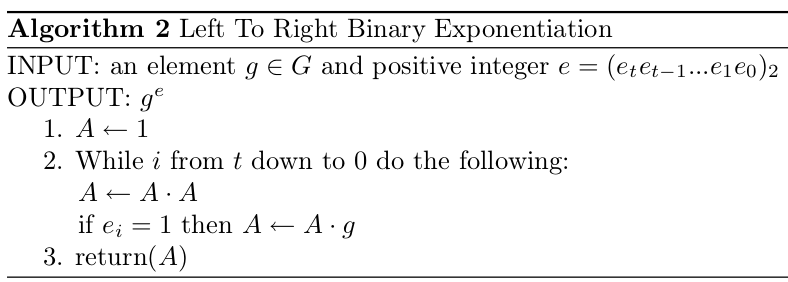

### Алгоритм. Проверка по заданному основанию с двоичным возведением в степень слева направо

**Вход:** нечётное число $n\ge5$ и основание $b$, $2\le b\le n-2$.

Вычисляем $b^{n-1}\bmod n$, дополнительно проверяя появление нетривиального квадратного корня из единицы.

Запишем показатель в двоичной системе:
$$
e=n-1=(e_k e_{k-1}\ldots e_0)_2.
$$
Биты просматриваем **от старшего к младшему**, то есть слева направо. Переменная $k$ задаёт индекс старшего бита, а не число раундов теста.

1. Присвоить $A\leftarrow1$.
2. Для $i=k,k-1,\ldots,0$:
   - Вычислить $S\leftarrow A^2\bmod n$.
   - Если $S=1$, но $A\ne1$ и $A\ne n-1$, вернуть **«Составное»**: найден нетривиальный квадратный корень из единицы.
   - Присвоить $A\leftarrow S$.
   - Если $e_i=1$, присвоить $A\leftarrow A\cdot b\bmod n$.
3. Если $A\ne1$, вернуть **«Составное»**: сравнение Ферма не выполнено.
4. Иначе вернуть **«Проверка по основанию b пройдена»**.

Положительный результат одной проверки **не доказывает простоту** $n$.

Алгоритм использует те же арифметические операции, что и библиотечная `mod_pow`, но здесь выбран порядок обработки битов **слева направо** и добавлена проверка промежуточных значений.

### Задание 4.22

Реализуйте один раунд `Miller_Rabin(p, base)` по приведённому алгоритму. Проверьте число 3825123056546412941 по основанию 6. Сформулируйте вывод, который позволяет сделать один раунд.

In [32]:
# Ваше решение

def Miller_Rabin(p, base):
    """Один проход слева направо. True — проверка по основанию пройдена, False — составное.

    По пути ловим квадрат 1, полученный из остатка, отличного от ±1.
    Один True простоту не доказывает.
    """
    n = p
    e = n - 1
    A = 1
    # Индекс старшего бита, а не число раундов теста.
    for i in range(e.bit_length() - 1, -1, -1):
        S = (A * A) % n
        if S == 1 and A != 1 and A != n - 1:
            return False
        A = S
        if (e >> i) & 1:
            A = (A * base) % n
    if A != 1:
        return False
    return True


number = 3825123056546412941
verdict = Miller_Rabin(number, 6)
print(f"Miller_Rabin({number}, 6) = {verdict}")
assert verdict is True
# Простые не должны отвергаться: у них нет нетривиального корня из 1 и выполнена теорема Ферма.
assert all(Miller_Rabin(prime, 2) for prime in primes(300) if prime >= 5)
assert Miller_Rabin(561, 2) is False
print(
    "Раунд по основанию 6 пройден. Один пройденный раунд простоту не доказывает:\n"
    "тот же ответ бывает и у сильно псевдопростого числа.\n"
    "Составность этим вызовом не установлена."
)


Miller_Rabin(3825123056546412941, 6) = True
Раунд по основанию 6 пройден. Один пройденный раунд простоту не доказывает:
тот же ответ бывает и у сильно псевдопростого числа.
Составность этим вызовом не установлена.


### Задание 4.23

Напишите `is_prime_MR(n, t=50)` с тем же интерфейсом и теми же диапазонами, что у окончательной `is_prime_mr`. Для отдельного основания вызывайте `Miller_Rabin(n, a)`. Проверьте число Бельфегора $1000000000000066600000000000001$ и объясните гарантию результата [[10]](#lit_10).

In [33]:
# Ваше решение

def is_prime_MR(n, t=50):
    """Те же пороги, что у is_prime_mr. Отдельное основание проверяет Miller_Rabin, а не miller_rabin_det."""
    if type(t) is not int or t < 1:
        raise ValueError("t должно быть положительным целым")
    if n < 2:
        return False
    for prime in _TRIAL_PRIMES:
        if n == prime:
            return True
        if n % prime == 0:
            return False
    if n < _MR_LIMIT:
        for a in _MR_BASES:
            if not Miller_Rabin(n, a):
                return False
        return True
    for _round in range(t):
        a = randint(2, n - 2)
        if not Miller_Rabin(n, a):
            return False
    return True


# На малом отрезке обе организации теста обязаны совпасть с точной проверкой.
for n in range(-5, 500):
    assert is_prime_MR(n) is is_prime_mr(n) is is_prime_fast(n)
# 25 326 001 не делится на простые <= 997 и проходит основания 2, 3, 5.
# Основание 7 из фиксированного набора обнаруживает составность и в этой версии.
assert is_prime_MR(25_326_001) is False
assert is_prime_MR(1009) is True

belphegor = 1000000000000066600000000000001
verdict = is_prime_MR(belphegor)
print("число Бельфегора:", verdict)
print("бит:", belphegor.bit_length(), ", меньше 2^64:", belphegor < _MR_LIMIT)
assert verdict is True
assert belphegor >= _MR_LIMIT
print(
    "Число больше 2^64, поэтому сработала вероятностная ветвь, а не набор из 12 оснований.\n"
    "True значит, что 50 случайных раундов пройдены. Для фиксированного составного\n"
    "вероятность такого ответа меньше 4^{-50}. Это не доказательство простоты.\n"
    "Источник [10] называет число простым, но этот факт не выводится из одного вызова функции."
)


число Бельфегора: True
бит: 100 , меньше 2^64: False
Число больше 2^64, поэтому сработала вероятностная ветвь, а не набор из 12 оснований.
True значит, что 50 случайных раундов пройдены. Для фиксированного составного
вероятность такого ответа меньше 4^{-50}. Это не доказательство простоты.
Источник [10] называет число простым, но этот факт не выводится из одного вызова функции.


### 4.3.3. Сравнение времени выполнения

### Задание 4.24

С помощью `time.perf_counter()` измерьте среднее время вызова `is_prime_mr`, `is_prime_MR` и `sympy.isprime` на составном числе 234987928347928347928347928734987398792837491 и простом числе Мерсенна $2^{127}-1$. Для учебных функций задайте одинаковое число раундов. Представьте результаты в микросекундах и объясните влияние раннего выхода.

In [34]:
# Ваше решение

from sympy import isprime

composite = 234987928347928347928347928734987398792837491
mersenne = 2**127 - 1
rounds = 50
repeats = 20


def average_microseconds(check):
    """Среднее время одного вызова. Это один замер, секунды не подгоняются."""
    start = time.perf_counter()
    for _repeat in range(repeats):
        check()
    return (time.perf_counter() - start) / repeats * 1_000_000


print("составное делится на 7:", composite % 7 == 0)
print("2^127-1 больше 2^64:", mersenne >= 2**64)
print(f"раундов у учебных функций: {rounds}, повторов среднего: {repeats}")

samples = (
    ("is_prime_mr, составное", lambda: is_prime_mr(composite, rounds)),
    ("is_prime_MR, составное", lambda: is_prime_MR(composite, rounds)),
    ("sympy.isprime, составное", lambda: isprime(composite)),
    ("is_prime_mr, 2^127-1", lambda: is_prime_mr(mersenne, rounds)),
    ("is_prime_MR, 2^127-1", lambda: is_prime_MR(mersenne, rounds)),
    ("sympy.isprime, 2^127-1", lambda: isprime(mersenne)),
)
for title, check in samples:
    verdict = check()
    elapsed = average_microseconds(check)
    print(f"{title}: ответ {verdict}, среднее {elapsed:.1f} мкс")

print(
    "Составное делится на 7, поэтому обе учебные функции выходят на пробном делении\n"
    "и раунды Миллера—Рабина не начинают. 2^127-1 простое и больше 2^64, малого\n"
    "делителя нет, и обе функции проходят все 50 раундов. Ранний выход и делает\n"
    "составное заметно быстрее простого при одинаковом t.\n"
    "sympy.isprime — другая реализация. Её время нельзя читать как ту же оценку 4^{-t},\n"
    "а положительный ответ для числа больше 2^64 сам по себе ещё не доказательство простоты.\n"
    "Числа выше — один эксперимент: повтор даст другие микросекунды."
)


составное делится на 7: True
2^127-1 больше 2^64: True
раундов у учебных функций: 50, повторов среднего: 20
is_prime_mr, составное: ответ False, среднее 0.3 мкс
is_prime_MR, составное: ответ False, среднее 0.2 мкс
sympy.isprime, составное: ответ False, среднее 0.2 мкс
is_prime_mr, 2^127-1: ответ True, среднее 2029.0 мкс
is_prime_MR, 2^127-1: ответ True, среднее 2045.8 мкс
sympy.isprime, 2^127-1: ответ True, среднее 51.0 мкс
Составное делится на 7, поэтому обе учебные функции выходят на пробном делении
и раунды Миллера—Рабина не начинают. 2^127-1 простое и больше 2^64, малого
делителя нет, и обе функции проходят все 50 раундов. Ранний выход и делает
составное заметно быстрее простого при одинаковом t.
sympy.isprime — другая реализация. Её время нельзя читать как ту же оценку 4^{-t},
а положительный ответ для числа больше 2^64 сам по себе ещё не доказательство простоты.
Числа выше — один эксперимент: повтор даст другие микросекунды.


### Задание 4.25

    
Последовательность **чисел Ферма** задаётся формулой
$$
F_n=2^{2^n}+1,\qquad n\ge0.
$$

Примените функции `is_prime_mr` и `is_prime_MR` к числам $F_n$ для $0\le n\le10$. Для каждой проверки укажите один из результатов:

- **«Составное»**, если функция вернула `False`.
- **«Простое»**, если функция вернула `True` и $F_n<2^{64}$: в этом диапазоне реализована детерминированная проверка.
- **«Тест пройден; простота не доказана»**, если функция вернула `True` и $F_n\ge2^{64}$: в этом диапазоне проверка вероятностная.

Сопоставьте результаты с `sympy.isprime`. Для больших чисел положительный ответ `sympy.isprime` также не следует автоматически считать доказательством простоты: необходимо учитывать гарантии используемого метода.

Для каких чисел составность установлена? Для каких простота доказана реализованным тестом? Остались ли числа, для которых получен только вероятностный положительный ответ?

In [35]:
# Ваше решение

from sympy import isprime


def describe(verdict, number):
    """Три исхода из условия: составность, доказанная простота ниже 2^64, вероятностный успех выше."""
    if verdict is False:
        return "Составное"
    if number < 2**64:
        return "Простое"
    return "Тест пройден; простота не доказана"


print(f"{'n':>2} {'бит':>5}  is_prime_mr                         is_prime_MR                         sympy")
for n in range(11):
    number = 2 ** (2**n) + 1
    by_mr = describe(is_prime_mr(number), number)
    by_MR = describe(is_prime_MR(number), number)
    by_sympy = isprime(number)
    print(f"{n:>2} {number.bit_length():>5}  {by_mr:<35} {by_MR:<35} {by_sympy}")
    assert by_mr == by_MR
    if n <= 4:
        # F0..F4 простые и меньше 2^64: срабатывает детерминированная ветвь.
        assert by_mr == "Простое" and by_sympy is True
    else:
        # F5 ловится делителем 641. Более поздние составные находит свидетель сильного теста.
        assert by_mr == "Составное" and by_sympy is False

print(
    "Составность установлена для F5..F10: функция вернула False, а это доказательство.\n"
    "F5 = 641*6700417, делитель 641 не больше 997, поэтому хватает пробного деления.\n"
    "Простота доказана реализованным тестом для F0..F4: все они меньше 2^64.\n"
    "F0..F3 совпадают с простыми из списка до 997, F4 = 65537 проходит фиксированные основания.\n"
    "Вероятностного положительного ответа в этой таблице не осталось.\n"
    "False у sympy.isprime тоже устанавливает составность. True для числа >= 2^64\n"
    "было бы только свидетельством метода SymPy, а не автоматическим доказательством;\n"
    "среди F0..F10 таких ответов нет."
)


 n   бит  is_prime_mr                         is_prime_MR                         sympy
 0     2  Простое                             Простое                             True
 1     3  Простое                             Простое                             True
 2     5  Простое                             Простое                             True
 3     9  Простое                             Простое                             True
 4    17  Простое                             Простое                             True
 5    33  Составное                           Составное                           False
 6    65  Составное                           Составное                           False
 7   129  Составное                           Составное                           False
 8   257  Составное                           Составное                           False
 9   513  Составное                           Составное                           False
10  1025  Составное                  

## 4.4. От теста простоты к генерации параметров: `find_p_g`

В `03_2026` (§3.7, задание 3.16) мы проверяли первообразный корень через простые делители порядка группы. Для простого p это делители p−1. В §3.8 и задании 3.20 появились безопасные простые и подгруппа простого порядка. Тогда использовались небольшие числа и пробное деление. Теперь Миллер—Рабин позволяет проверять большие кандидаты, поэтому логично объединить эти идеи в генератор параметров.

**Главное препятствие:** быстрый тест простоты p не делает факторизацию p−1 быстрой. Поэтому строим p так, чтобы разложение p−1 было известно заранее.

### 4.4.1. Безопасное простое заданной длины

Пусть L≥4. Выбираем нечётного кандидата q ровно из L−1 бит с помощью `random_exact_bits(L-1) | 1`. Проверяем q функцией `is_prime_mr(q, t)`. Если проверка пройдена, полагаем p=2q+1 и проверяем p. При неуспехе выбираем новое q. Тогда p имеет ровно L бит и p−1=2q. Само разложение p−1 вычислять не требуется.

Для больших чисел результат вероятностного теста означает **вероятно простое**. Доказательства ниже предполагают действительную простоту p и q; положительный тест не заменяет эту предпосылку. Оценку $4^{-t}$ для фиксированного составного кандидата нельзя автоматически объявлять вероятностью ошибки всей генерации.

### Задание 4.26. Генерация безопасного простого

Напишите `generate_safe_prime(bits, t=50)`, возвращающую `(p, q)`.

- Используйте `random_exact_bits` из библиотеки курса и проверенную `is_prime_mr` этого ноутбука.
- Требуйте целое bits≥4 и положительное целое t; недопустимые параметры отклоняйте через `ValueError`.
- Проверяйте q раньше p. Считайте число кандидатов и время в отдельном эксперименте.
- Начните с 12–20 бит: проверьте `p == 2*q + 1`, битовые длины и простоту обоих чисел точной `is_prime_fast`.
- Затем увеличивайте длину постепенно. Не вызывайте `decompose(p-1)` и не стройте `ZnZ(p)` для больших p.

In [36]:
# Ваше решение

def generate_safe_prime(bits, t=50):
    """Пара (p, q): p = 2q + 1, у p ровно bits бит, оба числа проходят is_prime_mr.

    При bits <= 64 и p, и q меньше 2^64, поэтому is_prime_mr их доказывает.
    При bits >= 65 число p уже не меньше 2^64, и его положительный тест только вероятностный.
    Оценка 4^{-t} относится к одному фиксированному составному кандидату, не ко всей генерации.
    """
    if type(bits) is not int or bits < 4:
        raise ValueError("bits должно быть целым >= 4")
    if type(t) is not int or t < 1:
        raise ValueError("t должно быть положительным целым")
    while True:
        # Старший бит уже выставлен. Младший делаем единицей, длина от этого не меняется.
        q = random_exact_bits(bits - 1) | 1
        if not is_prime_mr(q, t):
            continue
        p = 2 * q + 1
        if is_prime_mr(p, t):
            return p, q


try:
    generate_safe_prime(3)
    raise AssertionError("bits < 4 должно быть отклонено")
except ValueError:
    pass
try:
    generate_safe_prime(12, 0)
    raise AssertionError("t = 0 должно быть отклонено")
except ValueError:
    pass


def counted_safe_prime(bits, t=50):
    """Тот же цикл, что у generate_safe_prime, плюс число просмотренных q и время."""
    start = time.perf_counter()
    attempts = 0
    while True:
        attempts += 1
        q = random_exact_bits(bits - 1) | 1
        if not is_prime_mr(q, t):
            continue
        p = 2 * q + 1
        if is_prime_mr(p, t):
            return p, q, attempts, time.perf_counter() - start


for bits in (12, 16, 20):
    p, q, attempts, elapsed = counted_safe_prime(bits)
    assert p == 2 * q + 1
    assert p.bit_length() == bits
    assert q.bit_length() == bits - 1
    # До 20 бит точный перебор делителей ещё уместен и подтверждает оба числа.
    assert is_prime_fast(p) and is_prime_fast(q)
    check_p, check_q = generate_safe_prime(bits)
    assert check_p == 2 * check_q + 1 and is_prime_fast(check_p) and is_prime_fast(check_q)
    print(
        f"{bits} бит: p={p}, q={q}, кандидатов q: {attempts}, время {elapsed * 1000:.1f} мс"
    )

for bits in (32, 48):
    p, q, attempts, elapsed = counted_safe_prime(bits)
    assert p == 2 * q + 1
    assert p.bit_length() == bits and q.bit_length() == bits - 1
    # p < 2^64, поэтому положительный is_prime_mr здесь всё ещё доказательство.
    # decompose(p-1) не вызываем: разложение и так известно, это 2q.
    assert p < 2**64
    print(
        f"{bits} бит: битовая длина p проверена, кандидатов q: {attempts}, "
        f"время {elapsed * 1000:.1f} мс"
    )

print(
    "q проверяется раньше p. Число кандидатов случайно: повтор эксперимента даст другое.\n"
    "Пока bits <= 64, оба числа меньше 2^64 и is_prime_mr доказывает их простоту.\n"
    "Начиная с 65 бит p >= 2^64, и ответ теста для p только вероятностный."
)


12 бит: p=2879, q=1439, кандидатов q: 2, время 0.0 мс
16 бит: p=57923, q=28961, кандидатов q: 118, время 0.3 мс
20 бит: p=723959, q=361979, кандидатов q: 159, время 0.6 мс
32 бит: битовая длина p проверена, кандидатов q: 14, время 0.2 мс
48 бит: битовая длина p проверена, кандидатов q: 67, время 0.4 мс
q проверяется раньше p. Число кандидатов случайно: повтор эксперимента даст другое.
Пока bits <= 64, оба числа меньше 2^64 и is_prime_mr доказывает их простоту.
Начиная с 65 бит p >= 2^64, и ответ теста для p только вероятностный.


### 4.4.2. Почему для первообразного корня достаточно одной степени

Для простых p=2q+1 и q критерий из теоремы 3.3 ноутбука 3 имеет вид

$$\operatorname{ord}_p(g)=2q\iff g^q\not\equiv1\pmod p\quad\text{и}\quad g^2\not\equiv1\pmod p.$$

Выберем 2≤g≤p−2. Уравнение g²≡1 по простому модулю имеет только корни ±1, которые исключены диапазоном. Поэтому остаётся одна проверка:

$$\boxed{\operatorname{ord}_p(g)=2q\iff g^q\not\equiv1\pmod p,\qquad 2\le g\le p-2.}$$

При истинной простоте p результат этой степени равен 1 или −1. Можно проверять `pow(g, q, p) == p-1`. Если предполагаемые p,q получены вероятностным тестом, необычный остаток не следует принимать как подтверждение порядка.

### Задание 4.27. Специализированный поиск корня

Напишите `find_g_safe(p, q)`, последовательно проверяющую g=2,3,...,p−2 и возвращающую первый g с `pow(g, q, p) == p-1`. Предусловие: p,q — простые и p=2q+1, p≥5. Проверяйте соотношение параметров; простоту на каждом шаге повторно не тестируйте. Если кандидат не найден, сообщите об ошибке входных параметров.

Это поиск **наименьшего** первообразного корня. Случайный поиск может быть отдельным вариантом, но не гарантирует минимальность.

Для небольших p сопоставьте результат с библиотечными `primitive_root(p)`, `is_primitive_root(g, p, p-1)` и `multiplicative_order(g, p, p-1)`. Для больших p используйте известное разложение {2,q}, а не общую функцию, которая может повторно запускать пробное деление.

Самопроверка: p=23, q=11, наименьший корень g=5; 5^11≡22, 5²≡2 (mod 23).

In [37]:
# Ваше решение

def find_g_safe(p, q):
    """Наименьший g из 2..p-2 с g^q ≡ -1 (mod p).

    При простых p = 2q + 1 это и есть наименьший первообразный корень.
    Простоту на каждом шаге заново не проверяем. Если корня нет, предпосылка ложна.
    """
    if type(p) is not int or type(q) is not int or p < 5 or p != 2 * q + 1:
        raise ValueError("нужны целые p, q с p = 2*q + 1 и p >= 5")
    for g in range(2, p - 1):
        # Сравнение из условия задания: остаток p-1 и есть -1 по модулю p.
        if pow(g, q, p) == p - 1:
            return g
    raise ValueError("первообразный корень не найден: проверьте предпосылки p и q")


assert find_g_safe(23, 11) == 5
assert pow(5, 11, 23) == 22
assert pow(5, 2, 23) == 2
assert primitive_root(23) == 5
assert is_primitive_root(5, 23, 22)
assert multiplicative_order(5, 23, 22) == 22
print("p=23, q=11, наименьший корень g=5; 5^11 ≡ 22, 5^2 ≡ 2 (mod 23)")

# 16 бит ещё малы: библиотечный порядок с известным p-1 здесь уместен.
p, q = generate_safe_prime(16)
g = find_g_safe(p, q)
assert g == primitive_root(p)
assert is_primitive_root(g, p, p - 1)
assert multiplicative_order(g, p, p - 1) == p - 1
print(f"16 бит: p={p}, q={q}, g={g}, порядок {p - 1}")

# Для большего p общее разложение не запускаем: множители p-1 заранее равны 2 и q.
p, q = generate_safe_prime(32)
g = find_g_safe(p, q)
assert pow(g, q, p) == p - 1
assert pow(g, 2, p) != 1
print(f"32 бит: g={g}, g^q ≡ -1 и g^2 ≢ 1. decompose(p-1) не вызывался.")

try:
    find_g_safe(15, 7)
    raise AssertionError("у составного 15 = 2*7+1 корня с остатком 14 нет")
except ValueError:
    pass


p=23, q=11, наименьший корень g=5; 5^11 ≡ 22, 5^2 ≡ 2 (mod 23)
16 бит: p=59063, q=29531, g=5, порядок 59062
32 бит: g=2, g^q ≡ -1 и g^2 ≢ 1. decompose(p-1) не вызывался.


### Задание 4.28. Объединяем шаги в `find_p_g`

Реализуйте `find_p_g(bits, t=50)`, возвращающую **тройку `(p, q, g)`**:

```text
(p, q) ← generate_safe_prime(bits, t)
g ← find_g_safe(p, q)
вернуть (p, q, g)
```

Сохраняем также q, поскольку она понадобится для порядка подгруппы и выбора секретных показателей. Документируйте вероятностный характер простоты при больших входах.

In [38]:
# Ваше решение

def find_p_g(bits, t=50):
    """Тройка (p, q, g). q нужна дальше как порядок подгруппы и граница секретных показателей.

    При bits <= 64 простота p и q доказана детерминированной ветвью is_prime_mr.
    При больших bits положительный тест p только вероятностный: 4^{-t} ограничивает
    ошибку на одном фиксированном составном кандидате, а не вероятность ошибки генерации.
    """
    p, q = generate_safe_prime(bits, t)
    g = find_g_safe(p, q)
    return p, q, g


p, q, g = find_p_g(12)
assert p == 2 * q + 1
assert g == find_g_safe(p, q)
assert is_prime_fast(p) and is_prime_fast(q)
assert pow(g, q, p) == p - 1
print(f"find_p_g(12) = ({p}, {q}, {g})")
print(
    "q сохраняем вместе с p и g: порядок подгруппы равен q, секретные показатели берут из 1..q-1.\n"
    "Для 12 бит оба простых меньше 2^64, тест их доказывает. Для входа от 65 бит\n"
    "простота p этой функцией уже не доказывается."
)


find_p_g(12) = (3467, 1733, 2)
q сохраняем вместе с p и g: порядок подгруппы равен q, секретные показатели берут из 1..q-1.
Для 12 бит оба простых меньше 2^64, тест их доказывает. Для входа от 65 бит
простота p этой функцией уже не доказывается.


### 4.4.3. От всей группы к подгруппе простого порядка

В задании 3.20 ноутбука 3 образующий подгруппы получали возведением в квадрат. Теперь, если g — первообразный корень, положим h=g² mod p. Тогда

$$\operatorname{ord}_p(h)=\frac{2q}{\gcd(2,2q)}=q.$$

**g порождает всю группу порядка 2q, h — подгруппу порядка q.** Оба числа вместе с p,q являются открытыми параметрами; факторизацию p−1 не скрывают.

### Задание 4.29. Подготовка к следующим ноутбукам

1. Для полученной тройки вычислите h=g² mod p; проверьте h≠1 и h^q≡1 (mod p).
2. На малом примере p=23 получите h=2 и проверьте порядок библиотечной функцией.
3. Повторите обмен Диффи—Хеллмана из задания 3.20 с основанием h и секретами 1≤x_A,x_B≤q−1. Для степеней используйте `mod_pow`.
4. Объясните: Диффи—Хеллман согласует общий секрет, а не шифрует сообщение. Далее эти параметры можно использовать в учебном разборе Эль-Гамаля; пространство сообщений и требования безопасности будут отдельной темой.
5. Сравните время генерации (p,q) и поиска g; не включайте полное перечисление группы в измерения.

Для воспроизводимых учебных экспериментов допускается фиксируемый генератор случайных чисел. Выбор источника случайности для криптографических секретов рассматривается отдельно; `random` не следует выдавать за криптографический генератор.

In [39]:
# Ваше решение

# Тройка для протокола. 20 бит ещё проверяются точным тестом и печатаются целиком.
p, q, g = find_p_g(20)
assert is_prime_fast(p) and is_prime_fast(q)

# h = g^2 порождает подгруппу порядка q, если g — первообразный корень.
h = mod_pow(g, 2, p)
assert h != 1
assert mod_pow(h, q, p) == 1
print(f"p={p}, q={q}, g={g}, h=g^2 mod p={h}")
print("h ≠ 1 и h^q ≡ 1. При простом q отсюда порядок h равен q: других делителей нет.")

# Малый контрольный пример из задания: корень 5, квадрат даёт 2, порядок 2 равен 11.
assert find_g_safe(23, 11) == 5
h_small = mod_pow(5, 2, 23)
assert h_small == 2
assert multiplicative_order(h_small, 23, 22) == 11
print(f"для p=23 получаем h={h_small}, порядок {multiplicative_order(2, 23, 22)}")

# Секреты фиксируем seed только ради повторяемого учебного прогона.
# random не является криптографическим генератором секретов.
random.seed(2026)
x_a = random.randrange(1, q)
x_b = random.randrange(1, q)
A = mod_pow(h, x_a, p)
B = mod_pow(h, x_b, p)
K_a = mod_pow(B, x_a, p)
K_b = mod_pow(A, x_b, p)
print(f"x_A={x_a}, x_B={x_b}")
print(f"A={A}, B={B}")
print(f"K_A={K_a}, K_B={K_b}")
assert K_a == K_b
print(
    "K_A = B^{x_A} = (h^{x_B})^{x_A} = h^{x_A x_B} = (h^{x_A})^{x_B} = A^{x_B} = K_B.\n"
    "Диффи—Хеллман согласует общий секрет. Сообщение он не шифрует: по каналу идут только A и B.\n"
    "Эти же p, q, h дальше можно брать в учебном разборе Эль-Гамаля.\n"
    "Пространство сообщений и требования безопасности там будут отдельной темой."
)

# Время генерации (p, q) и время поиска g. Всю группу не перечисляем.
start = time.perf_counter()
p_big, q_big = generate_safe_prime(32)
prime_seconds = time.perf_counter() - start
start = time.perf_counter()
g_big = find_g_safe(p_big, q_big)
root_seconds = time.perf_counter() - start
assert pow(g_big, q_big, p_big) == p_big - 1
print(
    f"32 бит: генерация (p, q) заняла {prime_seconds * 1000:.1f} мс, "
    f"поиск g={g_big} занял {root_seconds * 1000:.1f} мс"
)
print(
    "Поиск пары перебирает много кандидатов q, пока оба числа не пройдут тест.\n"
    "Поиск корня идёт с g=2 и обычно останавливается на одном из первых значений:\n"
    "для безопасного простого первообразных корней около половины группы.\n"
    "Полный список группы в замер не входит. Повтор даст другие миллисекунды."
)


p=971207, q=485603, g=5, h=g^2 mod p=25
h ≠ 1 и h^q ≡ 1. При простом q отсюда порядок h равен q: других делителей нет.
для p=23 получаем h=2, порядок 11
x_A=62454, x_B=167502
A=817422, B=606199
K_A=601293, K_B=601293
K_A = B^{x_A} = (h^{x_B})^{x_A} = h^{x_A x_B} = (h^{x_A})^{x_B} = A^{x_B} = K_B.
Диффи—Хеллман согласует общий секрет. Сообщение он не шифрует: по каналу идут только A и B.
Эти же p, q, h дальше можно брать в учебном разборе Эль-Гамаля.
Пространство сообщений и требования безопасности там будут отдельной темой.
32 бит: генерация (p, q) заняла 0.3 мс, поиск g=2 занял 0.0 мс
Поиск пары перебирает много кандидатов q, пока оба числа не пройдут тест.
Поиск корня идёт с g=2 и обычно останавливается на одном из первых значений:
для безопасного простого первообразных корней около половины группы.
Полный список группы в замер не входит. Повтор даст другие миллисекунды.


## 4.5. Что переносим в `crypto_math/number_theory.py`

После выполнения заданий перенесите в библиотеку функции из таблицы. Проверьте их на граничных значениях.

| Функция | Контракт и назначение |
|---|---|
| `miller_rabin_round(n, a)` | Один сильный тест: False — свидетель составности, True — раунд пройден. При переносе используйте это имя для функции `miller_rabin_det`. |
| `miller_rabin(n, t=50)` | Ровно t независимых раундов; обработка малых n и валидация t. |
| `is_prime_mr(n, t=50)` | Предварительное деление на малые простые; фиксированные основания в доказанном диапазоне; вероятностная ветвь выше него. |
| `generate_safe_prime(bits, t=50)` | Пара (p,q), p=2q+1, заданная длина p. |
| `find_g_safe(p, q)` | Наименьший первообразный корень при оговорённых предпосылках. |
| `find_p_g(bits, t=50)` | Тройка (p,q,g). |

Сохраняем `is_prime_fast` как точный учебный тест для небольших чисел; не подменяем его незаметно вероятностной функцией. `Fermat`, `luk`, полный перебор `strong_liar`, альтернативные `Miller_Rabin` и `is_prime_MR`, а также `mr_error_bound` пока остаются в ноутбуке как исследовательские примеры.

**Проверки перед переносом:** n<2, n=2,3, чётные n, t≤0; сравнение с `is_prime_fast` на малом диапазоне в обе стороны; фиксированные основания на известных псевдопростых; пороги детерминированной ветви; битовые длины и порядки для малых безопасных простых. Различать тест одного основания и тест простоты. После переноса перезапустить ядро и импортировать готовые функции из библиотеки.

## 4.6. Литература

### Основная литература

<a id="lit_1"></a>**[1]** Menezes A. J., van Oorschot P. C., Vanstone S. A. *Handbook of Applied Cryptography*. — CRC Press, 1996.
- §4.2.1, определения 4.6–4.7 и алгоритм 4.9 — тест Ферма; определение 4.10 и утверждение 4.11 — числа Кармайкла и критерий Корсельта.
- §4.2.3, утверждения 4.20, 4.23, 4.25; определение 4.21; алгоритм 4.24; определение 4.29 и таблица 4.1 — сильный тест и фиксированные основания.
- §4.3, утверждение 4.38, с. 143, и замечание 4.39, с. 143–144 — критерий Люка; §4.4, §4.6 — генерация простых и образующих.
- [Глава 4, официальный PDF](https://cacr.uwaterloo.ca/hac/about/chap4.pdf).

<a id="lit_2"></a>**[2]** Маховенко Е. Б. *Теоретико-числовые методы в криптографии*. — М. : Гелиос АРВ, 2006.
- Пример 5.3 — задание 4.3 и рисунок 71.png; примеры 5.13–5.14 — рисунки 73.png и 74.png. 

<a id="lit_3"></a>**[3]** Нестеренко А. Ю. *Теоретико-числовые методы в криптографии*. — М. : МИЭМ, 2012. — 224 с.
- Вводный текст раздела 4.1 о вероятностных проверках простоты.
- [Карточка издания](https://publications.hse.ru/books/68297432).

### Дополнительная литература

<a id="lit_4"></a>**[4]** Alford W. R., Granville A., Pomerance C. *There are infinitely many Carmichael numbers*. — Annals of Mathematics. — 1994. — Vol. 140. — P. 703–722.
- Введение: историческая справка о Корсельте и Кармайкле.
- [Авторская копия](https://dms.umontreal.ca/~andrew/PDF/carmichael.pdf).

<a id="lit_5"></a>**[5]** Sorenson J. P., Webster J. *Strong Pseudoprimes to Twelve Prime Bases*. — Mathematics of Computation. — 2017. — Vol. 86. — P. 985–1003.
- Теорема 1.1: ψ12 > 2^64; источник полного набора оснований в задании 4.20.
- [Препринт](https://arxiv.org/abs/1509.00864).

<a id="lit_6"></a>**[6]** [SymPy Documentation: isprime](https://docs.sympy.org/latest/modules/ntheory.html#sympy.ntheory.primetest.isprime).
- Справка по независимой проверке в задании 4.20.

<a id="lit_7"></a>**[7]** Cormen T. H., Leiserson C. E., Rivest R. L. *Introduction to Algorithms*. — 1st ed. — MIT Press / McGraw-Hill, 1990.
- §33.8, процедура WITNESS — вариант Миллера—Рабина с проверками внутри двоичного возведения в степень. Номер раздела относится к первому изданию.
- [Электронный текст главы 33](https://bobson.ludost.net/books/algo/book6/chap33.htm).

<a id="lit_8"></a>**[8]** Jiang Y., Deng Y. *Strong pseudoprimes to the first 9 prime bases*. — Авторский препринт, 2012.
- Порог для первых девяти простых оснований в разделе о фиксированных основаниях.
- [arXiv:1207.0063](https://arxiv.org/abs/1207.0063).

<a id="lit_9"></a>**[9]** [Wikipedia: Strong pseudoprime](https://en.wikipedia.org/wiki/Strong_pseudoprime).
- Справочная ссылка в задании 4.16; доказанные пороги цитируются по научным источникам выше.

<a id="lit_10"></a>**[10]** [Википедия: Простое число Бельфегора](https://ru.wikipedia.org/wiki/Простое_число_Бельфегора).
- Справочная ссылка в задании 4.23.